# 📈 MOD-10 — Regresión Continua de Rendimiento Arrocero

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martín Naranjo Escobar

---

## 📋 Descripción del módulo

Este módulo predice el **rendimiento arrocero (t/ha) como variable continua pura**, sin conversión a clases ni evaluación por matrices de confusión o curvas ROC. A diferencia del MOD-09, todas las métricas son de regresión: RMSE, MAE, R², MAPE e intervalos de confianza al 95% por bootstrap.

### Diferencia clave respecto al MOD-09

| Aspecto | MOD-09 | MOD-10 |
|---------|--------|--------|
| Tipo de salida | Regresión + clasificación 3 clases | **Regresión continua pura** |
| Métricas | RMSE, matrices confusión, AUC | **RMSE, MAE, R², MAPE, IC95%** |
| Modelos | Ridge, RF, XGB, LGB | Ridge, **ElasticNet**, RF, XGB, LGB |
| Selección features | PCA sobre X completo | **Boruta → PCA sobre features confirmadas** |
| Exclusión leakage | Parcial | **PATRON_AREA_PROD + COLS_EXCLUIR_X ampliado** |

### Procesos adicionales incorporados

| # | Proceso | Justificación |
|---|---------|---------------|
| 1 | Exclusión Área/Producción (leakage) | `Rendimiento = Producción / Área` → leakage matemático directo |
| 2 | Transformación log del target | Reduce asimetría si `|skew| > 0.8` |
| 3 | **Boruta** selección robusta | Descarta features ruido antes de PCA |
| 4 | IC95 bootstrap sobre RMSE | Cuantifica incertidumbre del error de generalización |
| 5 | ElasticNet (L1+L2) | Selección implícita de features irrelevantes |
| 6 | Curvas de aprendizaje LOPO | ¿Cuántos periodos estabilizan el error? |
| 7 | PCA sin leakage temporal | Ajustado dentro del fold |
| 8 | Ensemble ponderado RMSE_LOPO | Combina modelos ponderando por rendimiento por fold |
| 9 | Permutation Importance LOPO | Importancia evaluada en fold de TEST |
| 10 | Análisis de residuales avanzado | Shapiro-Wilk, Durbin-Watson, sesgo por periodo |
| 11 | Tabla predicciones municipio-periodo | Con IC `[±1.96×RMSE]` por observación |

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD10_regresion_continua.ipynb      ← Este archivo
└── data/
    └── master/
        ├── A3_DF_Features.parquet           ← Entrada desde MOD-08
        ├── M2_Boruta_ranking.csv            ← Ranking features Boruta
        ├── M2_Boruta_Features.png           ← Gráfico clasificación Boruta
        ├── M2_Distribucion_Target.png       ← Histograma + Q-Q + log(y)
        ├── M2_Curvas_Aprendizaje.png        ← Curvas de aprendizaje LOPO
        ├── M2_Permutation_Importance.png    ← Importancia por permutación
        ├── M2_SHAP_Beeswarm.png             ← SHAP del modelo ganador
        ├── M2_Residuales_Avanzado.png       ← Análisis residuales 4 paneles
        ├── M2_Dashboard_Regresion.png       ← Dashboard 9 paneles final
        ├── M2_resultados_regresion.xlsx     ← LOPO + Perm.Imp + SHAP (6 hojas)
        ├── M2_modelo_final.pkl              ← Modelo ganador serializado
        ├── M2_PCA_regresion.pkl             ← PCA + scaler sobre X_boruta
        ├── M2_ensemble.pkl                  ← Ensemble ponderado
        ├── M2_shap_values.pkl               ← SHAP values
        └── M2_predicciones_municipio.xlsx   ← Predicciones + IC por observación
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Archivo | Origen |
|------|---------|--------|
| **Entrada** | `data/master/A3_DF_Features.parquet` | MOD-08 |
| Salida 1 | `M2_Boruta_ranking.csv` + `M2_Boruta_Features.png` | Este módulo |
| Salida 2 | `M2_resultados_regresion.xlsx` (6 hojas) | Este módulo |
| Salida 3 | `M2_modelo_final.pkl` | Este módulo |
| Salida 4 | `M2_PCA_regresion.pkl` | Este módulo |
| Salida 5 | `M2_ensemble.pkl` | Este módulo |
| Salida 6 | `M2_predicciones_municipio.xlsx` | Este módulo |

---

## 🔗 Dependencias entre módulos

```
MOD-08 → A3_DF_Features.parquet
         └─→ [MOD-10] Regresión Continua
                  ├─→ Exclusión Área/Producción (leakage matemático)
                  ├─→ Transformación log(y) si asimetría > 0.8
                  ├─→ Boruta → X_boruta (features confirmadas)
                  ├─→ PCA sobre X_boruta (sin leakage temporal)
                  ├─→ Ensemble ponderado por RMSE_LOPO
                  └─→ M2_modelo_final.pkl
```

> **Arquitectura v2.0:** Usa `cod_divipola` como llave universal. Requiere que **MOD-00** a **MOD-08** hayan sido ejecutados previamente.

---

## 🔄 Flujo de ejecución

| # | Celda | Descripción |
|---|-------|-------------|
| 1 | Entorno | Instalación: `sklearn`, `xgboost`, `lightgbm`, `shap`, `scipy`, `boruta` |
| 2 | Rutas y parámetros | `COLS_EXCLUIR_X` ampliado, `PATRON_AREA_PROD`, 5 modelos, PCA, Bootstrap |
| 3 | Funciones | `lopo_cv()` con predicciones por fold, `lopo_cv_pca()` sin leakage, `resumir_lopo()` con IC95 |
| 4 | Cargar datos | Carga + exclusión Área/Producción + diagnóstico distribución target |
| 5 | Transformación log | Si `|asimetría| > 0.8`: `y_modelo = log(y)`. Histograma + Q-Q plot |
| 6 | **Boruta** | Selección robusta → `X_boruta`, `X_boruta_arr`. Guarda ranking y gráfico |
| 7 | LOPO 5 modelos | LOPO sobre `X_boruta_arr` con IC95 bootstrap. Sin conversión a clases |
| 8 | Curvas aprendizaje | RMSE por N periodos sobre `X_boruta_arr`. Diagnóstico de suficiencia histórica |
| 9 | PCA | K componentes (varianza ≥ 90%) sobre `X_boruta_arr`. Correlación vs target |
| 10 | LOPO RF+PCA | PCA ajustado dentro del fold. Tabla comparativa extendida 7 modelos |
| 11 | Ensemble | 5 modelos finales + ensemble ponderado por RMSE_LOPO fold a fold |
| 12 | Perm. Importance | Importancia por permutación en fold de TEST sobre `X_boruta_arr` |
| 13 | SHAP | SHAP del modelo ganador (features Boruta o componentes PCA) |
| 14 | Residuales | Shapiro-Wilk, Durbin-Watson, sesgo por periodo y rango de rendimiento |
| 15 | Predicciones | Tabla municipio-periodo: predicciones + IC `[±1.96×RMSE]` + MAE por depto |
| 16 | Dashboard | `M2_Dashboard_Regresion.png`: 9 paneles RMSE+IC95, curva aprendizaje, residuales |
| 17 | Guardar | Excel 6 hojas + PKL ganador, ensemble, PCA, SHAP |
| 18 | Resumen final | Procesos adicionales, archivos generados, tabla LOPO con IC95 |


---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

Instala `scikit-learn`, `xgboost`, `lightgbm`, `shap`, `openpyxl`, `pyarrow`, `scipy` y `boruta`. Importa todos los módulos necesarios incluyendo `scipy.stats` para los tests estadísticos de normalidad y autocorrelación del análisis de residuales.

In [1]:
# ============================================================
# MOD-10 — Modelado Predictivo Regresion Continua de Rendimiento
# Proyecto: Impacto Variabilidad Climatica en Produccion Arrocera
# Version  : 1.0
# Entrada  : data/master/A3_DF_Features.parquet   (MOD-08)
# Salidas  : data/master/M2_resultados_regresion.xlsx
#            data/master/M2_modelo_final.pkl
#            data/master/M2_PCA_regresion.pkl
# ============================================================
# Diferencia clave respecto a MOD-09:
#   MOD-09: predice Rendimiento (t/ha) y evalua con matrices
#           de confusion y curvas ROC (target convertido a
#           3 clases Bajo/Medio/Alto). Clasificacion.
#   MOD-10: predice Rendimiento (t/ha) directamente como
#           variable continua pura. Regresion. Sin conversion
#           a clases. Metricas: RMSE, MAE, R2, MAPE, IC95.
#
# Procesos adicionales incorporados en MOD-10:
#   1. Intervalo de confianza por Bootstrap en LOPO
#   2. Ensemble ponderado por RMSE_LOPO (stacking simple)
#   3. Analisis de residuales avanzado (normalidad, homocedasticidad)
#   4. Curvas de aprendizaje (learning curves LOPO)
#   5. PCA con seleccion de componentes predictivos (de MOD-09 v3.0)
#   6. Importancia de features estable (permutation importance LOPO)
#   7. Prediccion por municipio y periodo (tabla de resultados final)
# ============================================================
!pip install scikit-learn xgboost lightgbm shap openpyxl pyarrow scipy -q

import os, gc, time, warnings, pickle, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from scipy import stats

from sklearn.linear_model    import Ridge, ElasticNet
from sklearn.ensemble        import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing   import StandardScaler
from sklearn.decomposition   import PCA
from sklearn.inspection      import permutation_importance
from sklearn.metrics         import (mean_squared_error, mean_absolute_error,
                                     r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import ParameterGrid

from xgboost  import XGBRegressor
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
print('OK Librerias cargadas — MOD-10 Regresion Continua')


OK Librerias cargadas — MOD-10 Regresion Continua


---
## 📁 CELDA 2 — Configuración de rutas y parámetros

`COLS_EXCLUIR_X` ampliado con todas las variantes de Área y Producción (con/sin tilde, sufijos `_sem`, `_m1..m6`). `PATRON_AREA_PROD` para exclusión dinámica de variantes no listadas. Prefijo de salidas `M2_*` (distinto de MOD-09 que usa `M1_*`). `N_BOOTSTRAP=500` para IC95. `PCA_VARIANZA_OBJETIVO=0.90`.

In [2]:
# ============================================================
# CELDA 1 — Configuracion de rutas y parametros
# ============================================================

# ── Montaje robusto de Google Drive con reintentos ───────────
# El error 'mount failed' es transitorio en Colab: ocurre cuando
# el token OAuth caduca o hay un timeout de red. La funcion
# montar_drive() reintenta hasta 3 veces con force_remount=True.

from google.colab import drive
import time

def montar_drive(max_intentos=3, espera_seg=5):
    for intento in range(1, max_intentos + 1):
        try:
            if os.path.exists('/content/drive/MyDrive'):
                print('Google Drive ya estaba montado')
                return True
            drive.mount('/content/drive', force_remount=False)
            print('Google Drive montado correctamente')
            return True
        except Exception as e:
            print(f'   Intento {intento}/{max_intentos} fallido: {e}')
            if intento < max_intentos:
                print(f'   Reintentando con force_remount=True en {espera_seg}s...')
                time.sleep(espera_seg)
                try:
                    drive.mount('/content/drive', force_remount=True)
                    print('Google Drive montado con force_remount')
                    return True
                except Exception as e2:
                    print(f'   force_remount fallido: {e2}')
            else:
                print()
                print('ERROR: No se pudo montar Google Drive.')
                print('Soluciones:')
                print('  1. Entorno de ejecucion -> Reconectar y borrar entorno de ejecucion')
                print('  2. Ejecutar esta celda nuevamente')
                print('  3. Verificar conexion a internet y permisos de la cuenta')
                raise RuntimeError('Google Drive no disponible tras reintentos.')
    return False

montar_drive()

# Deteccion automatica de RUTA_BASE
RUTA_BASE = None
print()
print('Buscando carpeta del proyecto...')
for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive'):
    depth = dirpath.replace('/content/drive/MyDrive','').count(os.sep)
    if depth > 5:
        dirnames.clear(); continue
    if 'A3_DF_Features.parquet' in filenames:
        candidate = os.path.dirname(os.path.dirname(dirpath))
        if os.path.isdir(os.path.join(candidate,'data','master')):
            RUTA_BASE = candidate
            print(f'   Proyecto en: {RUTA_BASE}'); break

if RUTA_BASE is None:
    RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'
    print(f'   Usando ruta manual: {RUTA_BASE}')

RUTA_MASTER = os.path.join(RUTA_BASE, 'data', 'master')
os.makedirs(RUTA_MASTER, exist_ok=True)

# Archivos de entrada
ENTRADA_FEATURES  = os.path.join(RUTA_MASTER, 'A3_DF_Features.parquet')

# Archivos de salida — prefijo M2 (MOD-10)
SALIDA_RESULTADOS  = os.path.join(RUTA_MASTER, 'M2_resultados_regresion.xlsx')
SALIDA_MODELO_PKL  = os.path.join(RUTA_MASTER, 'M2_modelo_final.pkl')
SALIDA_PCA_PKL     = os.path.join(RUTA_MASTER, 'M2_PCA_regresion.pkl')
SALIDA_SHAP_PKL    = os.path.join(RUTA_MASTER, 'M2_shap_values.pkl')
SALIDA_ENSEMBLE_PKL= os.path.join(RUTA_MASTER, 'M2_ensemble.pkl')
SALIDA_PRED_XLS    = os.path.join(RUTA_MASTER, 'M2_predicciones_municipio.xlsx')

# ── Parametros de modelado ────────────────────────────────────
TARGET_COL    = 'Rendimiento (t/ha)'
SEMILLA       = 42

# Columnas a excluir de X
# EXCLUSION CRITICA: Area y Produccion son insumos del calculo
# Rendimiento = Produccion / Area. Incluirlas genera leakage
# matematico directo.
COLS_EXCLUIR_X = [
    # Identificadores y metadatos
    'Periodo','Departamento','Municipio','Anio','Ano','Año','Semestre',
    'Cultivo','Cuadrante','Es_Top500','Es_Top50',
    # Leakage matematico directo
    'Produccion (t)','Producción (t)',
    'Area (ha)','Área (ha)',
    'Area cosechada (ha)','Área cosechada (ha)',
    'Area sembrada (ha)','Área sembrada (ha)',
    'Produccion_total_t','Produccion_sem',
    'Area_sem','Area_cosechada_sem',
    # Target
    'Rendimiento (t/ha)',
]

# Patron dinamico para variantes no listadas (sufijos _m1..m6, _sem, _var)
PATRON_AREA_PROD = [
    'area', 'produccion', 'producción',
    'cosechada', 'sembrada', 'produccion_', 'area_',
]
COLS_EXCLUIR_IDENTIF = [
    'Codigo Dane','codigo_dane','codigo_municipio','DANE',
    'cod_divipola',
]

# PCA
PCA_VARIANZA_OBJETIVO = 0.90
PCA_VARIANZA_MIN_COMP = 0.01
PCA_MAX_COMPONENTES   = 30

# Bootstrap IC95
N_BOOTSTRAP = 500

# Hiperparametros — modelos de regresion pura (sin conversion a clases)
PARAMS_RIDGE = dict(alpha=10.0)
PARAMS_EN    = dict(alpha=0.1, l1_ratio=0.5, max_iter=5000)
PARAMS_RF    = dict(n_estimators=500, max_features='sqrt',
                    max_depth=None, min_samples_leaf=3,
                    random_state=SEMILLA, n_jobs=-1)
PARAMS_XGB   = dict(n_estimators=400, learning_rate=0.05, max_depth=4,
                    subsample=0.8, colsample_bytree=0.8,
                    reg_alpha=0.1, reg_lambda=1.0,
                    early_stopping_rounds=20, eval_metric='rmse',
                    random_state=SEMILLA, verbosity=0, n_jobs=-1)
PARAMS_LGB   = dict(n_estimators=400, learning_rate=0.05, num_leaves=15,
                    max_depth=4, subsample=0.8, colsample_bytree=0.8,
                    reg_alpha=0.1, reg_lambda=1.0, min_child_samples=5,
                    random_state=SEMILLA, n_jobs=-1, verbose=-1)

if not os.path.exists(ENTRADA_FEATURES):
    raise FileNotFoundError(
        'No se encontro A3_DF_Features.parquet.\n'
        'Ejecuta MOD-08 antes de continuar.'
    )

print()
print('Rutas configuradas:')
print(f'   Master   -> {RUTA_MASTER}')
print(f'   Entrada  -> A3_DF_Features.parquet OK')
print()
print('Parametros:')
print(f'   Target         : {TARGET_COL}  (continuo puro)')
print(f'   Semilla        : {SEMILLA}')
print(f'   PCA varianza   : >= {PCA_VARIANZA_OBJETIVO*100:.0f}%')
print(f'   Bootstrap IC95 : {N_BOOTSTRAP} iteraciones')
print(f'   Modelos        : Ridge, ElasticNet, RF, XGBoost, LightGBM')
print(f'   Nuevo          : Ensemble ponderado por RMSE_LOPO')


   Intento 1/3 fallido: mount failed
   Reintentando con force_remount=True en 5s...
Mounted at /content/drive
Google Drive montado con force_remount

Buscando carpeta del proyecto...
   Proyecto en: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II

Rutas configuradas:
   Master   -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master
   Entrada  -> A3_DF_Features.parquet OK

Parametros:
   Target         : Rendimiento (t/ha)  (continuo puro)
   Semilla        : 42
   PCA varianza   : >= 90%
   Bootstrap IC95 : 500 iteraciones
   Modelos        : Ridge, ElasticNet, RF, XGBoost, LightGBM
   Nuevo          : Ensemble ponderado por RMSE_LOPO


---
## 🔧 CELDA 3 — Funciones utilitarias

`lopo_cv()` devuelve `y_real` e `y_pred` individuales por fold (necesarios para análisis de residuales y tabla de predicciones). `lopo_cv_pca()` ajusta scaler+PCA dentro del fold para evitar leakage. `resumir_lopo()` calcula IC95 por bootstrap (500 iteraciones) sobre los RMSE de cada fold, permitiendo comparar modelos con evidencia estadística.

In [3]:
# ============================================================
# CELDA 2 — Funciones utilitarias
# Mejoras sobre MOD-09:
#   + calcular_metricas_regresion: agrega IC95 por bootstrap
#   + lopo_cv: devuelve predicciones por fold para analisis
#   + lopo_cv_pca: PCA dentro del fold (sin leakage)
#   + resumir_lopo: agrega IC95 de las metricas
# ============================================================

def calcular_metricas_regresion(y_true, y_pred, nombre=''):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    r2   = float(r2_score(y_true, y_pred))
    mape = float(mean_absolute_percentage_error(y_true, y_pred) * 100)
    if nombre:
        print(f'   {nombre:<22} RMSE={rmse:.4f}  MAE={mae:.4f}  '
              f'R2={r2:.4f}  MAPE={mape:.2f}%')
    return {'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}


def lopo_cv(modelo_cls, X, y, periodos,
            nombre='Modelo', is_xgb=False, is_lgb=False,
            escalar=False):
    '''
    Leave-One-Period-Out — regresion pura.
    Devuelve lista de dicts con metricas y predicciones por fold.
    Si escalar=True aplica StandardScaler dentro del fold.
    '''
    periodos_unicos = sorted(periodos.unique())
    resultados = []

    for per_test in periodos_unicos:
        mask_test  = (periodos == per_test)
        mask_train = ~mask_test
        X_tr, X_te = X[mask_train], X[mask_test]
        y_tr, y_te = y[mask_train], y[mask_test]

        if len(y_te) == 0:
            continue

        if escalar:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_te = sc.transform(X_te)

        modelo = copy.deepcopy(modelo_cls)
        try:
            if is_xgb:
                modelo.fit(X_tr, y_tr,
                           eval_set=[(X_te, y_te)], verbose=False)
            elif is_lgb:
                from lightgbm import early_stopping, log_evaluation
                modelo.fit(X_tr, y_tr, eval_set=[(X_te, y_te)],
                           callbacks=[early_stopping(20, verbose=False),
                                      log_evaluation(period=-1)])
            else:
                modelo.fit(X_tr, y_tr)

            y_pred = modelo.predict(X_te)
            m = calcular_metricas_regresion(y_te, y_pred)
            m['Periodo_test'] = per_test
            m['n_test']       = int(len(y_te))
            m['n_train']      = int(len(y_tr))
            m['y_real']       = y_te.tolist() if hasattr(y_te,'tolist') else list(y_te)
            m['y_pred']       = y_pred.tolist()
            resultados.append(m)
        except Exception as e:
            print(f'     Fold {per_test}: error — {e}')

    return resultados


def lopo_cv_pca(modelo_cls, X_orig, y, periodos, n_comp, semilla=42):
    '''
    LOPO con StandardScaler + PCA ajustados DENTRO de cada fold.
    Evita data leakage temporal del PCA.
    '''
    periodos_unicos = sorted(periodos.unique())
    resultados = []

    for per_test in periodos_unicos:
        mask_test  = (periodos == per_test)
        mask_train = ~mask_test
        X_tr_orig = X_orig[mask_train]
        X_te_orig = X_orig[mask_test]
        y_tr = y[mask_train]
        y_te = y[mask_test]

        if len(y_te) == 0:
            continue

        sc_fold  = StandardScaler()
        X_tr_sc  = sc_fold.fit_transform(X_tr_orig)
        X_te_sc  = sc_fold.transform(X_te_orig)

        n_c = min(n_comp, X_tr_sc.shape[0]-1, X_tr_sc.shape[1])
        pca_fold = PCA(n_components=n_c, random_state=semilla)
        X_tr_pca = pca_fold.fit_transform(X_tr_sc)
        X_te_pca = pca_fold.transform(X_te_sc)

        modelo = copy.deepcopy(modelo_cls)
        try:
            modelo.fit(X_tr_pca, y_tr)
            y_pred = modelo.predict(X_te_pca)
            m = calcular_metricas_regresion(y_te, y_pred)
            m['Periodo_test'] = per_test
            m['n_test']       = int(len(y_te))
            m['n_train']      = int(len(y_tr))
            m['y_real']       = y_te.tolist() if hasattr(y_te,'tolist') else list(y_te)
            m['y_pred']       = y_pred.tolist()
            resultados.append(m)
        except Exception as e:
            print(f'     Fold {per_test}: error — {e}')

    return resultados


def resumir_lopo(resultados, nombre, n_bootstrap=500):
    '''
    Calcula media +- std de metricas LOPO.
    Agrega IC95 por bootstrap sobre los valores por fold.
    '''
    df_r = pd.DataFrame(resultados)
    resumen = {'Modelo': nombre, 'n_folds': len(df_r)}

    for m in ['RMSE','MAE','R2','MAPE']:
        if m not in df_r.columns:
            continue
        vals = df_r[m].dropna().values
        resumen[f'{m}_mean'] = float(vals.mean())
        resumen[f'{m}_std']  = float(vals.std())

        # Bootstrap IC95
        rng = np.random.RandomState(42)
        boot_means = [
            rng.choice(vals, size=len(vals), replace=True).mean()
            for _ in range(n_bootstrap)
        ]
        resumen[f'{m}_IC95_lo'] = float(np.percentile(boot_means, 2.5))
        resumen[f'{m}_IC95_hi'] = float(np.percentile(boot_means, 97.5))

    print(f'   {nombre:<25}: '
          f'RMSE={resumen["RMSE_mean"]:.4f}+-{resumen["RMSE_std"]:.4f}  '
          f'IC95=[{resumen["RMSE_IC95_lo"]:.4f},{resumen["RMSE_IC95_hi"]:.4f}]  '
          f'R2={resumen["R2_mean"]:.4f}')
    return resumen, df_r


print('OK Funciones utilitarias cargadas (MOD-10)')
print('  lopo_cv()     - LOPO regresion con predicciones por fold')
print('  lopo_cv_pca() - LOPO con PCA sin leakage')
print('  resumir_lopo()- media+-std + IC95 bootstrap')


OK Funciones utilitarias cargadas (MOD-10)
  lopo_cv()     - LOPO regresion con predicciones por fold
  lopo_cv_pca() - LOPO con PCA sin leakage
  resumir_lopo()- media+-std + IC95 bootstrap


---
## 📥 CELDA 4 — Cargar datos y excluir Área/Producción

Carga `A3_DF_Features.parquet` y aplica exclusión triple: `COLS_EXCLUIR_X` + `COLS_EXCLUIR_IDENTIF` + `PATRON_AREA_PROD`. Diagnóstico de distribución del target: Shapiro-Wilk (normalidad), asimetría (skewness) y curtosis. Define `X_arr` y `y_arr` que Boruta necesita en la siguiente celda.

In [4]:
# ============================================================
# CELDA 3 — Cargar A3_DF_Features y preparar X, y
# ============================================================

print('Cargando A3_DF_Features.parquet...')
df_feat = pd.read_parquet(ENTRADA_FEATURES)

for col in ['Periodo','Departamento','Municipio']:
    if col in df_feat.columns:
        df_feat[col] = df_feat[col].astype(str).str.strip().str.upper()

print(f'   Shape      : {df_feat.shape[0]:,} x {df_feat.shape[1]}')
print(f'   Periodos   : {sorted(df_feat["Periodo"].unique())}')
print(f'   Municipios : {df_feat["Municipio"].nunique()}')

# Verificar target
if TARGET_COL not in df_feat.columns:
    alt = [c for c in df_feat.columns if 'endimiento' in c or 'Rend' in c]
    if alt:
        TARGET_COL = alt[0]
        print(f'   TARGET_COL ajustado a: {TARGET_COL}')
    else:
        raise KeyError(f'No se encontro columna de rendimiento.')

df_model = df_feat[df_feat[TARGET_COL].notna()].copy().reset_index(drop=True)
print(f'   Filas con target valido: {len(df_model):,}')

# Construir X: solo features climaticas puras
# Triple exclusion: lista explicita + identificadores + patron dinamico
cols_x = [
    c for c in df_model.columns
    if c not in COLS_EXCLUIR_X
    and not any(exc.lower() in c.lower() for exc in COLS_EXCLUIR_IDENTIF)
    and not any(p in c.lower() for p in PATRON_AREA_PROD)
    and df_model[c].dtype in ['float32','float64','int64','Int64','int32']
]

# Verificacion de trazabilidad
cols_leak = [
    c for c in df_model.columns
    if any(p in c.lower() for p in PATRON_AREA_PROD)
    and c not in COLS_EXCLUIR_X
    and df_model[c].dtype in ['float32','float64','int64','Int64','int32']
]
if cols_leak:
    print('Columnas adicionales excluidas por PATRON_AREA_PROD:')
    for c in cols_leak:
        print(f'   EXCLUIDA {c}')
else:
    print('PATRON_AREA_PROD: sin columnas adicionales')

cols_excluidas_ident = [
    c for c in df_model.columns
    if any(exc.lower() in c.lower() for exc in COLS_EXCLUIR_IDENTIF)
]
if cols_excluidas_ident:
    print(f'   Excluidos por identificador geografico: {cols_excluidas_ident}')

X = df_model[cols_x].copy()
y = df_model[TARGET_COL].copy().astype(float)

# Rellenar nulos residuales con mediana por columna
X = X.fillna(X.median(numeric_only=True))
for c in X.columns:
    if str(X[c].dtype).startswith('Int'):
        X[c] = X[c].astype('float32')

PERIODOS_SERIE = df_model['Periodo']
X_arr = X.values.astype(float)
y_arr = y.values.astype(float)

print(f'\n   Features (X) : {X.shape[1]} columnas')
print(f'   Target  (y)  : {TARGET_COL}  (CONTINUO PURO)')
print(f'   Rango target : {y_arr.min():.2f} - {y_arr.max():.2f} t/ha')
print(f'   Media target : {y_arr.mean():.2f} t/ha')
print(f'   Std target   : {y_arr.std():.2f} t/ha')
print(f'   Coef. variacion: {y_arr.std()/y_arr.mean()*100:.1f}%')
print()

# Diagnostico de distribucion del target
stat_sw, p_sw = stats.shapiro(y_arr[:min(len(y_arr), 5000)])
print('Distribucion del target (Rendimiento t/ha):')
print(f'   Shapiro-Wilk: W={stat_sw:.4f}  p={p_sw:.4f}  '
      f'({"Normal" if p_sw > 0.05 else "No normal"})')
asimetria = stats.skew(y_arr)
curtosis  = stats.kurtosis(y_arr)
print(f'   Asimetria   : {asimetria:.3f}  '
      f'({"simetrico" if abs(asimetria) < 0.5 else "asimetrico"})')
print(f'   Curtosis    : {curtosis:.3f}')
print()
if abs(asimetria) > 1.0:
    print('AVISO: asimetria alta - considerar transformacion log del target')
    print('       Se probara tanto con y original como con log(y) en CELDA 4b')

# Diagnostico de nulos
nulos = X.isna().sum().sum()
print(f'   Nulos en X: {nulos}')


Cargando A3_DF_Features.parquet...
   Shape      : 351 x 181
   Periodos   : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']
   Municipios : 58
   Filas con target valido: 351
PATRON_AREA_PROD: sin columnas adicionales
   Excluidos por identificador geografico: ['Código Dane departamento', 'Código Dane municipio']

   Features (X) : 163 columnas
   Target  (y)  : Rendimiento (t/ha)  (CONTINUO PURO)
   Rango target : 0.00 - 9.52 t/ha
   Media target : 6.43 t/ha
   Std target   : 1.75 t/ha
   Coef. variacion: 27.2%

Distribucion del target (Rendimiento t/ha):
   Shapiro-Wilk: W=0.8575  p=0.0000  (No normal)
   Asimetria   : -1.685  (asimetrico)
   Curtosis    : 4.217

AVISO: asimetria alta - considerar transformacion log del target
       Se probara tanto con y original como con log(y) en CELDA 4b
   Nulos en X: 0


---
## 📊 CELDA 5 — Evaluación de transformación log del target

Compara histograma + Q-Q plot del target original vs `log(y)`. Si `|asimetría| > 0.8` y `log(y)` es más simétrico: activa `USAR_LOG_TARGET=True` y define `y_modelo = log(y_arr)`. Las predicciones finales se retransforman con `exp()` para reportar en t/ha. Guarda `M2_Distribucion_Target.png`.

Target tiene valores <= 0: no se aplica log


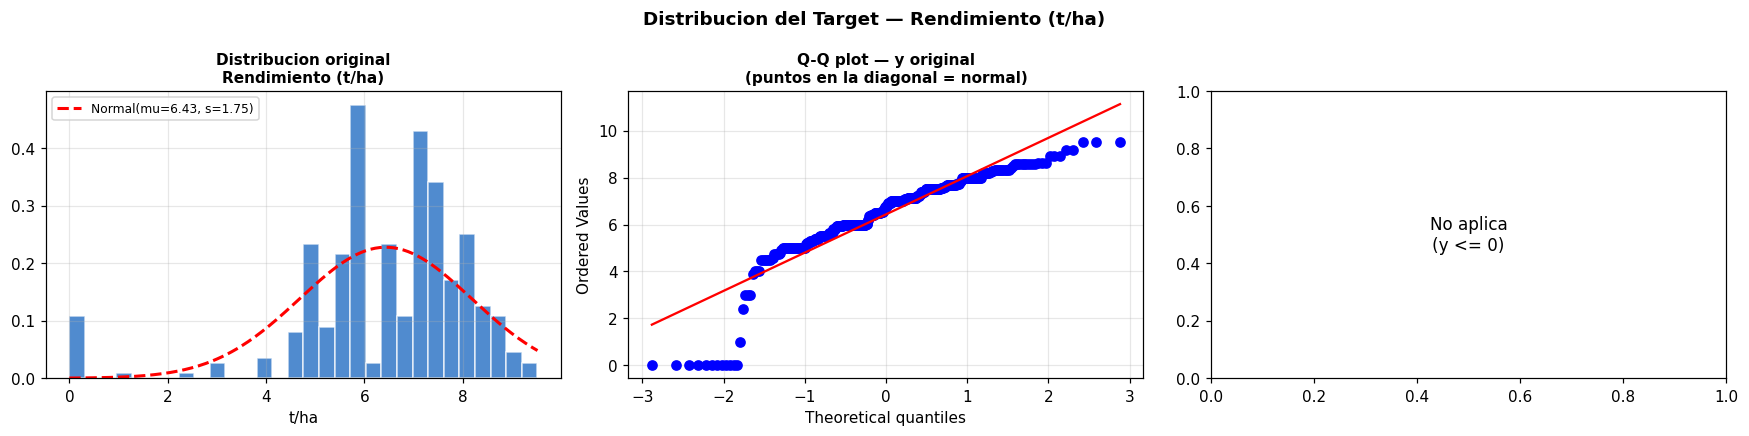


y_modelo shape: (351,)
USAR_LOG_TARGET: False


In [5]:
# ============================================================
# CELDA 4 — Evaluacion de transformacion del target
#
# PROCESO ADICIONAL vs MOD-09:
# El rendimiento en t/ha puede tener cola derecha (asimetria
# positiva). Los modelos lineales (Ridge, ElasticNet) asumen
# errores homoscedaticos: si el target tiene asimetria alta,
# la transformacion log(y) puede mejorar el ajuste lineal
# y reducir la influencia de outliers.
#
# Regla de decision:
#   |asimetria| > 0.8 Y min(y) > 0 -> probar log(y)
#   Si RMSE_LOPO(log) < RMSE_LOPO(original) -> usar log
#   En cualquier caso se reportan ambas versiones.
# ============================================================

USAR_LOG_TARGET = False   # se actualiza automaticamente

fig_target, axes_t = plt.subplots(1, 3, figsize=(16, 4))
fig_target.suptitle('Distribucion del Target — Rendimiento (t/ha)',
                    fontsize=12, fontweight='bold')

# Panel 1: Histograma y densidad — y original
axes_t[0].hist(y_arr, bins=30, color='#1565C0', alpha=0.75,
               edgecolor='white', density=True)
mu, sigma = y_arr.mean(), y_arr.std()
x_norm = np.linspace(y_arr.min(), y_arr.max(), 200)
axes_t[0].plot(x_norm, stats.norm.pdf(x_norm, mu, sigma),
              'r--', lw=2, label=f'Normal(mu={mu:.2f}, s={sigma:.2f})')
axes_t[0].set_title('Distribucion original\nRendimiento (t/ha)',
                    fontsize=10, fontweight='bold')
axes_t[0].set_xlabel('t/ha'); axes_t[0].legend(fontsize=8)
axes_t[0].grid(alpha=0.3)

# Panel 2: Q-Q plot — y original
stats.probplot(y_arr, dist='norm', plot=axes_t[1])
axes_t[1].set_title('Q-Q plot — y original\n(puntos en la diagonal = normal)',
                    fontsize=10, fontweight='bold')
axes_t[1].grid(alpha=0.3)

# Panel 3: Histograma — log(y) si aplica
if y_arr.min() > 0:
    y_log = np.log(y_arr)
    axes_t[2].hist(y_log, bins=30, color='#e74c3c', alpha=0.75,
                   edgecolor='white', density=True)
    mu_l, sigma_l = y_log.mean(), y_log.std()
    x_norm_l = np.linspace(y_log.min(), y_log.max(), 200)
    axes_t[2].plot(x_norm_l, stats.norm.pdf(x_norm_l, mu_l, sigma_l),
                  'r--', lw=2)
    axes_t[2].set_title('Distribucion log(y)\n(mas simetrica si hay asimetria)',
                        fontsize=10, fontweight='bold')
    axes_t[2].set_xlabel('log(t/ha)')
    axes_t[2].grid(alpha=0.3)

    stat_sw_log, p_sw_log = stats.shapiro(y_log[:min(len(y_log), 5000)])
    asimetria_log = stats.skew(y_log)
    print('Comparacion de normalizacion del target:')
    print(f'  y original  : Shapiro p={p_sw:.4f}  asimetria={asimetria:.3f}')
    print(f'  log(y)      : Shapiro p={p_sw_log:.4f}  asimetria={asimetria_log:.3f}')

    # Decision automatica
    if abs(asimetria) > 0.8 and abs(asimetria_log) < abs(asimetria):
        USAR_LOG_TARGET = True
        print()
        print('Decision: USAR log(y)')
        print('   Razon: asimetria original > 0.8 y log(y) es mas simetrico')
        print('   Efecto: modelos lineales y XGB se benefician de distribucion')
        print('           mas normal. Las predicciones se transforman de vuelta')
        print('           con exp(pred) para reportar en t/ha originales.')
        y_modelo = y_log
    else:
        print()
        print('Decision: USAR y original')
        print('   Razon: asimetria no justifica la transformacion log')
        y_modelo = y_arr
else:
    print('Target tiene valores <= 0: no se aplica log')
    y_modelo = y_arr
    axes_t[2].text(0.5, 0.5, 'No aplica\n(y <= 0)',
                  ha='center', va='center',
                  transform=axes_t[2].transAxes, fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_Distribucion_Target.png'),
            dpi=130, bbox_inches='tight')
plt.show()

y_modelo = np.array(y_modelo, dtype=float)
print(f'\ny_modelo shape: {y_modelo.shape}')
print(f'USAR_LOG_TARGET: {USAR_LOG_TARGET}')


---
## 🌲 CELDA 6 — Boruta: selección robusta de variables climáticas

Ejecuta Boruta sobre `X_arr` usando `y_modelo` como target (puede ser `log(y)` si se activó la transformación). Clasifica features como **Confirmada**, **Tentativa** o **Rechazada** en 50 iteraciones. Produce `X_boruta` y `X_boruta_arr` (confirmadas + tentativas) que reemplazan a `X_arr` en **todas** las celdas siguientes. Guarda `M2_Boruta_ranking.csv` y `M2_Boruta_Features.png`.

  BORUTA — Seleccion de variables climaticas relevantes

  X_arr shape  : (351, 163)  (prerequisito OK)
  y_modelo shape: (351,)  (prerequisito OK)
  n_estimators : 100  |  max_iter: 50  |  alpha: 0.05

Ejecutando Boruta sobre y_modelo (puede tardar 3-8 min)...
Iteration: 1 / 50
Iteration: 2 / 50
Iteration: 3 / 50
Iteration: 4 / 50
Iteration: 5 / 50
Iteration: 6 / 50
Iteration: 7 / 50
Iteration: 8 / 50
Iteration: 9 / 50
Iteration: 10 / 50
Iteration: 11 / 50
Iteration: 12 / 50
Iteration: 13 / 50
Iteration: 14 / 50
Iteration: 15 / 50
Iteration: 16 / 50
Iteration: 17 / 50
Iteration: 18 / 50
Iteration: 19 / 50
Iteration: 20 / 50
Iteration: 21 / 50
Iteration: 22 / 50
Iteration: 23 / 50
Iteration: 24 / 50
Iteration: 25 / 50
Iteration: 26 / 50
Iteration: 27 / 50
Iteration: 28 / 50
Iteration: 29 / 50
Iteration: 30 / 50
Iteration: 31 / 50
Iteration: 32 / 50
Iteration: 33 / 50
Iteration: 34 / 50
Iteration: 35 / 50
Iteration: 36 / 50
Iteration: 37 / 50
Iteration: 38 / 50
Iteration: 39 / 50
Iterat

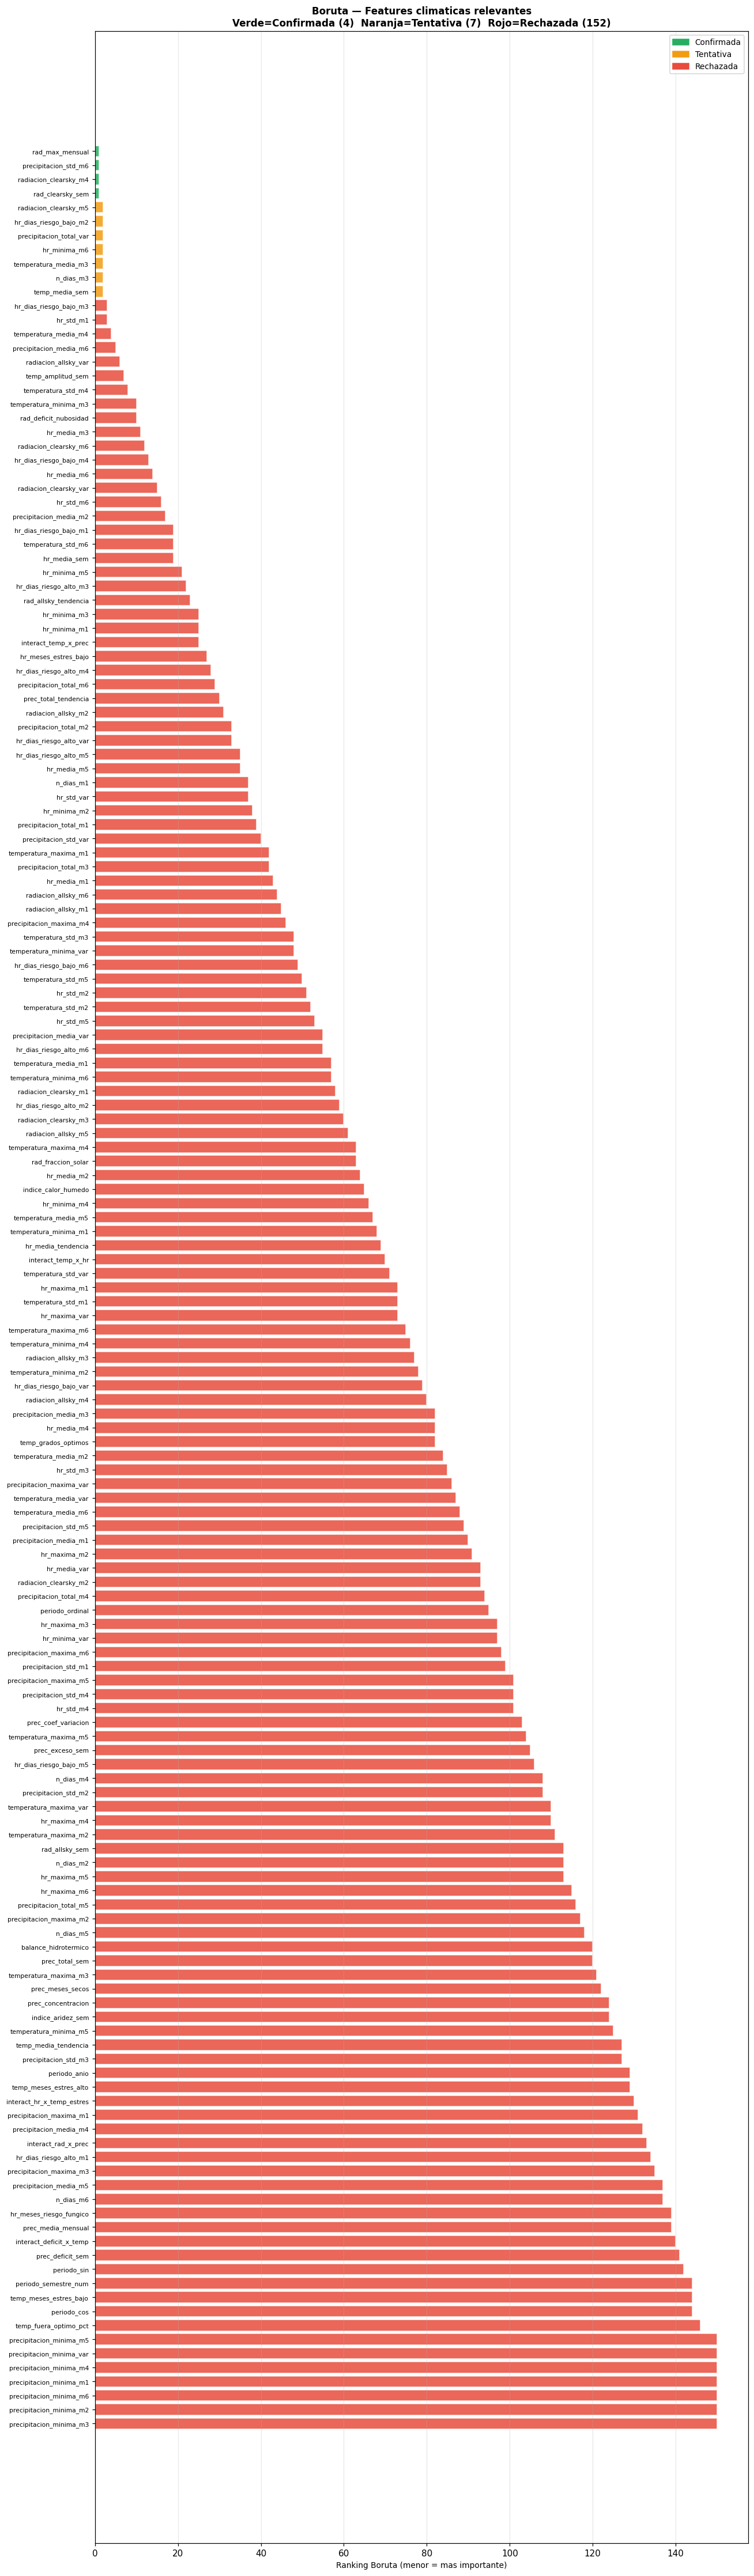

OK Grafico Boruta guardado: M2_Boruta_Features.png


In [6]:
# ============================================================
# BORUTA — Seleccion robusta de variables climaticas
# Prerequisitos: X_arr (celda 3), y_modelo (celda 4)
# Produce: X_boruta, X_boruta_arr, COLS_BORUTA
# ============================================================

try:
    from boruta import BorutaPy
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'boruta', '-q'], check=True)
    from boruta import BorutaPy

import time
from sklearn.ensemble import RandomForestRegressor as RFBoruta

sep = '='*65
print(sep)
print('  BORUTA — Seleccion de variables climaticas relevantes')
print(sep)
print()
print(f'  X_arr shape  : {X_arr.shape}  (prerequisito OK)')
print(f'  y_modelo shape: {y_modelo.shape}  (prerequisito OK)')
print(f'  n_estimators : 100  |  max_iter: 50  |  alpha: 0.05')
print()

rf_boruta = RFBoruta(
    n_estimators=100, max_depth=7, min_samples_leaf=3,
    random_state=SEMILLA, n_jobs=-1
)
boruta_selector = BorutaPy(
    estimator=rf_boruta, n_estimators='auto',
    max_iter=50, alpha=0.05, two_step=True,
    random_state=SEMILLA, verbose=1
)

print('Ejecutando Boruta sobre y_modelo (puede tardar 3-8 min)...')
t0_b = time.time()
boruta_selector.fit(X_arr, y_modelo)
print(f'Boruta completado en {time.time()-t0_b:.0f}s')
print()

mask_confirmadas = boruta_selector.support_
mask_tentativas  = boruta_selector.support_weak_
mask_rechazadas  = ~mask_confirmadas & ~mask_tentativas

cols_confirmadas = X.columns[mask_confirmadas].tolist()
cols_tentativas  = X.columns[mask_tentativas].tolist()
cols_rechazadas  = X.columns[mask_rechazadas].tolist()

print(sep)
print('  RESULTADO BORUTA')
print(sep)
print(f'  Confirmadas : {len(cols_confirmadas):>4}')
print(f'  Tentativas  : {len(cols_tentativas):>4}')
print(f'  Rechazadas  : {len(cols_rechazadas):>4}')
print()

ranking_boruta = boruta_selector.ranking_
df_boruta = (
    pd.DataFrame({'feature': X.columns, 'ranking': ranking_boruta})
    .sort_values('ranking').reset_index(drop=True)
)
df_boruta['estado'] = df_boruta['feature'].map(
    lambda f: 'Confirmada' if f in cols_confirmadas
              else ('Tentativa' if f in cols_tentativas else 'Rechazada')
)

print('Features CONFIRMADAS y TENTATIVAS:')
print(f'  {"Rank":>5}  {"Estado":<12}  Feature')
print(f'  {"-"*60}')
for _, row in df_boruta[df_boruta['estado'] != 'Rechazada'].iterrows():
    marca = 'OK' if row['estado'] == 'Confirmada' else '? '
    print(f'  {marca} {int(row["ranking"]):>4}  {row["estado"]:<12}  {row["feature"]}')

COLS_BORUTA = cols_confirmadas + cols_tentativas
if len(COLS_BORUTA) == 0:
    print('AVISO: Boruta sin confirmaciones. Usando todas las features.')
    COLS_BORUTA = X.columns.tolist()

X_boruta     = X[COLS_BORUTA].copy()
X_boruta_arr = X_boruta.values.astype(float)

print()
print(sep)
print(f'  X_boruta: {X_boruta.shape[0]:,} obs x {X_boruta.shape[1]} features')
print(f'  Reduccion: {X.shape[1]} -> {X_boruta.shape[1]} '
      f'({(1-X_boruta.shape[1]/X.shape[1])*100:.1f}% eliminadas)')
print(sep)
print()
print('X_boruta_arr listo para celdas siguientes.')

df_boruta.to_csv(
    os.path.join(RUTA_MASTER, 'M2_Boruta_ranking.csv'), index=False
)

# Visualizacion
fig_b, ax_b = plt.subplots(figsize=(12, max(6, len(df_boruta)*0.25)))
colores_b = {'Confirmada':'#27ae60','Tentativa':'#f39c12','Rechazada':'#e74c3c'}
df_bv = df_boruta.sort_values('ranking', ascending=False)
ax_b.barh(range(len(df_bv)), df_bv['ranking'],
          color=[colores_b[e] for e in df_bv['estado']],
          edgecolor='white', alpha=0.85)
ax_b.set_yticks(range(len(df_bv)))
ax_b.set_yticklabels(df_bv['feature'], fontsize=7)
ax_b.set_xlabel('Ranking Boruta (menor = mas importante)', fontsize=9)
ax_b.set_title(
    f'Boruta — Features climaticas relevantes\n'
    f'Verde=Confirmada ({len(cols_confirmadas)})  '
    f'Naranja=Tentativa ({len(cols_tentativas)})  '
    f'Rojo=Rechazada ({len(cols_rechazadas)})',
    fontsize=11, fontweight='bold'
)
from matplotlib.patches import Patch
ax_b.legend(handles=[
    Patch(color='#27ae60', label='Confirmada'),
    Patch(color='#f39c12', label='Tentativa'),
    Patch(color='#e74c3c', label='Rechazada'),
], fontsize=9)
ax_b.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_Boruta_Features.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('OK Grafico Boruta guardado: M2_Boruta_Features.png')


---
## 🏋️ CELDA 7 — Validación LOPO — 5 modelos de regresión pura

LOPO sobre Ridge, ElasticNet, RF, XGBoost y LightGBM usando `X_boruta_arr`. ElasticNet (L1+L2) es nuevo respecto a MOD-09: con features climáticas correlacionadas, L1 zerifica implícitamente las irrelevantes. Todos los resultados incluyen IC95 bootstrap. Sin conversión a clases.

In [7]:
# ============================================================
# CELDA 5 — Validacion LOPO — 5 modelos de regresion pura
#
# Modelos vs MOD-09:
#   MOD-09: Ridge, RF, XGB, LGB (4 modelos)
#   MOD-10: Ridge, ElasticNet, RF, XGB, LGB (5 modelos)
#     + ElasticNet: combina L1 (seleccion features) y L2
#       (regularizacion). Mas robusto que Ridge cuando hay
#       muchas features irrelevantes (L1 las zerifica).
#
# Sin conversion a clases: el target es siempre continuo.
# Las metricas son RMSE, MAE, R2, MAPE + IC95 bootstrap.
# ============================================================

sep = '='*65
print(sep)
print('  VALIDACION LEAVE-ONE-PERIOD-OUT (LOPO) — REGRESION CONTINUA')
print(sep)
print()
print(f'  Target : {TARGET_COL}  (continuo, sin conversion a clases)')
print(f'  Folds  : {PERIODOS_SERIE.nunique()}')
print(f'  IC95   : bootstrap {N_BOOTSTRAP} iteraciones')
print()

# Escalado para modelos lineales
scaler_lin = StandardScaler()
# Modelos lineales escalan X_boruta_arr
X_scaled   = scaler_lin.fit_transform(X_boruta_arr)

# 0. Ridge
print('0. Ridge (baseline lineal):')
ridge_m = Ridge(**PARAMS_RIDGE)
lopo_ridge = lopo_cv(ridge_m, X_scaled, y_modelo, PERIODOS_SERIE,
                     nombre='Ridge', escalar=False)
res_ridge, df_lopo_ridge = resumir_lopo(lopo_ridge, 'Ridge', N_BOOTSTRAP)

# 1. ElasticNet
print()
print('1. ElasticNet (L1+L2):')
en_m = ElasticNet(**PARAMS_EN)
lopo_en = lopo_cv(en_m, X_scaled, y_modelo, PERIODOS_SERIE,
                  nombre='ElasticNet', escalar=False)
res_en, df_lopo_en = resumir_lopo(lopo_en, 'ElasticNet', N_BOOTSTRAP)

# 2. Random Forest
print()
print('2. Random Forest:')
rf_m = RandomForestRegressor(**PARAMS_RF)
lopo_rf = lopo_cv(rf_m, X_boruta_arr, y_modelo, PERIODOS_SERIE, nombre='RF')
res_rf, df_lopo_rf = resumir_lopo(lopo_rf, 'Random Forest', N_BOOTSTRAP)

# 3. XGBoost
print()
print('3. XGBoost:')
xgb_m = XGBRegressor(**PARAMS_XGB)
lopo_xgb = lopo_cv(xgb_m, X_boruta_arr, y_modelo, PERIODOS_SERIE,
                   nombre='XGB', is_xgb=True)
res_xgb, df_lopo_xgb = resumir_lopo(lopo_xgb, 'XGBoost', N_BOOTSTRAP)

# 4. LightGBM
print()
print('4. LightGBM:')
lgb_m = LGBMRegressor(**PARAMS_LGB)
lopo_lgb = lopo_cv(lgb_m, X_boruta_arr, y_modelo, PERIODOS_SERIE,
                   nombre='LGB', is_lgb=True)
res_lgb, df_lopo_lgb = resumir_lopo(lopo_lgb, 'LightGBM', N_BOOTSTRAP)

# Tabla comparativa
RESUMEN_LOPO = pd.DataFrame([res_ridge, res_en, res_rf, res_xgb, res_lgb])
NAMES_MOD    = ['Ridge','ElasticNet','Random Forest','XGBoost','LightGBM']
LOPO_DFS     = [df_lopo_ridge, df_lopo_en, df_lopo_rf, df_lopo_xgb, df_lopo_lgb]

print()
print(sep)
print('  TABLA COMPARATIVA LOPO — Regresion Continua')
print(sep)
print()
print(f'  {"Modelo":<22}  {"RMSE":>8}  {"+-std":>6}  {"IC95":>20}  {"R2":>7}  {"MAPE":>7}')
print(f'  {"-"*75}')
for _, row in RESUMEN_LOPO.iterrows():
    ic = f'[{row["RMSE_IC95_lo"]:.4f},{row["RMSE_IC95_hi"]:.4f}]'
    print(f'  {row["Modelo"]:<22}  {row["RMSE_mean"]:>8.4f}  '
          f'{row["RMSE_std"]:>6.4f}  {ic:>20}  '
          f'{row["R2_mean"]:>7.4f}  {row["MAPE_mean"]:>6.1f}%')

mejor_idx    = RESUMEN_LOPO['RMSE_mean'].idxmin()
mejor_nombre = RESUMEN_LOPO.loc[mejor_idx, 'Modelo']
print()
print(f'  Modelo con menor RMSE_LOPO: {mejor_nombre}')
print(f'  Media del target           : {y_modelo.mean():.4f} t/ha')
print(f'  RMSE relativo (mejor mod.) : {RESUMEN_LOPO.loc[mejor_idx,"RMSE_mean"]/y_modelo.mean()*100:.1f}%')
print()
if USAR_LOG_TARGET:
    print('NOTA: Metricas calculadas sobre log(y).')
    print('      Las predicciones finales se transforman con exp() para reportar en t/ha.')


  VALIDACION LEAVE-ONE-PERIOD-OUT (LOPO) — REGRESION CONTINUA

  Target : Rendimiento (t/ha)  (continuo, sin conversion a clases)
  Folds  : 10
  IC95   : bootstrap 500 iteraciones

0. Ridge (baseline lineal):
   Ridge                    : RMSE=1.6649+-0.4926  IC95=[1.3433,1.9503]  R2=-0.0206

1. ElasticNet (L1+L2):
   ElasticNet               : RMSE=1.6024+-0.4589  IC95=[1.3117,1.8778]  R2=0.1327

2. Random Forest:
   Random Forest            : RMSE=1.4707+-0.4100  IC95=[1.2223,1.7292]  R2=0.2624

3. XGBoost:
   XGBoost                  : RMSE=1.4468+-0.3899  IC95=[1.2048,1.6871]  R2=0.2922

4. LightGBM:
   LightGBM                 : RMSE=1.4694+-0.3888  IC95=[1.2267,1.7113]  R2=0.2704

  TABLA COMPARATIVA LOPO — Regresion Continua

  Modelo                      RMSE   +-std                  IC95       R2     MAPE
  ---------------------------------------------------------------------------
  Ridge                     1.6649  0.4926       [1.3433,1.9503]  -0.0206  111387678554886816.0

---
## 📈 CELDA 8 — Curvas de aprendizaje LOPO

Para N_train = 2..9: entrena con los N primeros periodos sobre `X_boruta_arr` y evalúa en el siguiente. Si el RMSE sigue bajando al agregar periodos, el dataset actual es insuficiente. Estabilización antes de 6 periodos indica suficiencia del histórico disponible. Guarda `M2_Curvas_Aprendizaje.png`.

Calculando curvas de aprendizaje LOPO...
(Cuantos periodos de entrenamiento estabilizan el RMSE?)



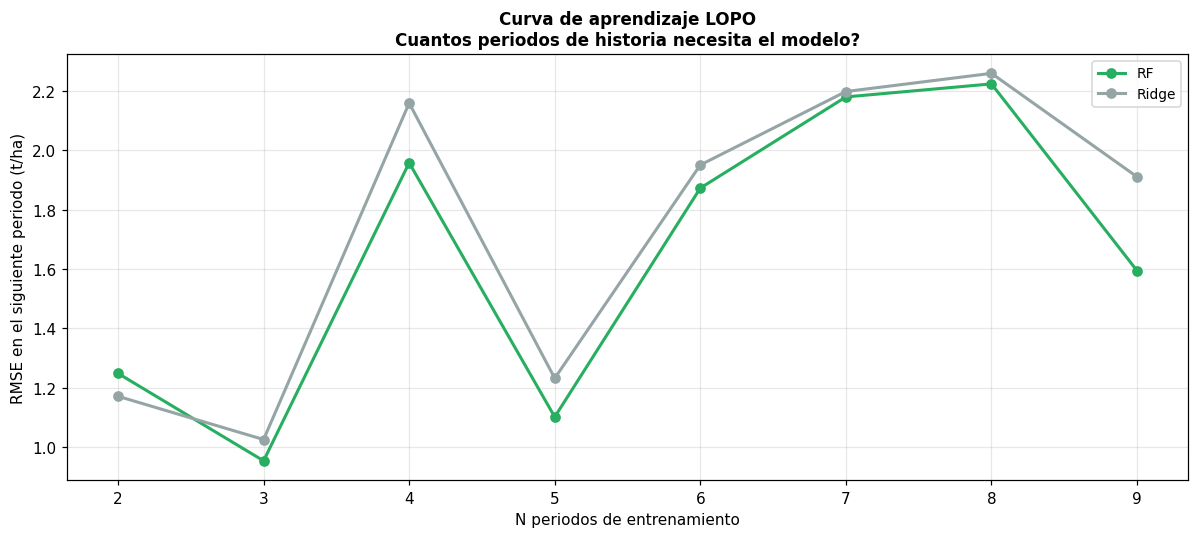

Interpretacion curva RF:
   RMSE min en curva  : 0.9544 t/ha
   RMSE max en curva  : 2.2237 t/ha
   Estabilizacion     : aproximadamente con 8 periodos

IMPLICACION: si el RMSE sigue bajando al agregar periodos,
el dataset actual es insuficiente y la prediccion mejoraria
con datos de semestres adicionales (2025A, 2025B, etc.).


In [8]:
# ============================================================
# CELDA 6 — Curvas de aprendizaje LOPO (PROCESO ADICIONAL)
#
# Pregunta clave: cuantos periodos de entrenamiento necesita
# el modelo para estabilizar el RMSE_LOPO?
#
# Metodologia:
#   Para cada n_periodos_train = 2, 3, 4, ..., max-1:
#     - Usar los ULTIMOS n periodos como train (mas recientes)
#     - El fold de test es siempre el periodo siguiente
#     - Calcular RMSE_test
#   Si el RMSE se estabiliza con 5-6 periodos, los 10 periodos
#   actuales son suficientes. Si sigue bajando, el modelo
#   necesita mas datos historicos.
#
# Se calcula para RF (mejor modelo de arboles tipicamente)
# y Ridge (baseline lineal) para comparar.
# ============================================================

print('Calculando curvas de aprendizaje LOPO...')
print('(Cuantos periodos de entrenamiento estabilizan el RMSE?)')
print()

periodos_ordenados = sorted(PERIODOS_SERIE.unique())
N_PER = len(periodos_ordenados)

resultados_lc = {'RF': [], 'Ridge': []}

for n_train in range(2, N_PER):
    # Usar los primeros n_train periodos para entrenar
    # y el (n_train+1)-esimo como test
    per_train_list = periodos_ordenados[:n_train]
    per_test_lc    = periodos_ordenados[n_train]

    mask_tr = PERIODOS_SERIE.isin(per_train_list)
    mask_te = (PERIODOS_SERIE == per_test_lc)

    X_tr = X_boruta_arr[mask_tr]; y_tr = y_modelo[mask_tr]
    X_te = X_boruta_arr[mask_te]; y_te = y_modelo[mask_te]

    if len(y_te) == 0:
        continue

    # RF
    rf_lc = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3,
        random_state=SEMILLA, n_jobs=-1
    )
    rf_lc.fit(X_tr, y_tr)
    rmse_rf_lc = float(np.sqrt(mean_squared_error(y_te, rf_lc.predict(X_te))))
    resultados_lc['RF'].append((n_train, per_test_lc, rmse_rf_lc))

    # Ridge
    sc_lc = StandardScaler()
    ridge_lc = Ridge(alpha=10.0)
    ridge_lc.fit(sc_lc.fit_transform(X_tr), y_tr)
    rmse_ridge_lc = float(np.sqrt(mean_squared_error(
        y_te, ridge_lc.predict(sc_lc.transform(X_te))
    )))
    resultados_lc['Ridge'].append((n_train, per_test_lc, rmse_ridge_lc))

# Visualizacion
fig_lc, ax_lc = plt.subplots(figsize=(11, 5))

for modelo_lc, color_lc in [('RF','#27ae60'), ('Ridge','#95a5a6')]:
    datos_lc = resultados_lc[modelo_lc]
    n_trains  = [d[0] for d in datos_lc]
    rmses_lc  = [d[2] for d in datos_lc]
    ax_lc.plot(n_trains, rmses_lc, 'o-', ms=6, lw=2,
               color=color_lc, label=modelo_lc)

ax_lc.set_xlabel('N periodos de entrenamiento', fontsize=10)
ax_lc.set_ylabel('RMSE en el siguiente periodo (t/ha)', fontsize=10)
ax_lc.set_title(
    'Curva de aprendizaje LOPO\n'
    'Cuantos periodos de historia necesita el modelo?',
    fontsize=11, fontweight='bold'
)
ax_lc.legend(fontsize=9)
ax_lc.grid(alpha=0.3)
ax_lc.set_xticks(range(2, N_PER))

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_Curvas_Aprendizaje.png'),
            dpi=130, bbox_inches='tight')
plt.show()

# Interpretacion
datos_rf_lc = resultados_lc['RF']
if datos_rf_lc:
    rmse_lc_vals = [d[2] for d in datos_rf_lc]
    n_estabiliza = None
    for i in range(1, len(rmse_lc_vals)):
        cambio_rel = abs(rmse_lc_vals[i] - rmse_lc_vals[i-1]) / (rmse_lc_vals[i-1] + 1e-9)
        if cambio_rel < 0.05 and n_estabiliza is None:
            n_estabiliza = datos_rf_lc[i][0]
    print(f'Interpretacion curva RF:')
    print(f'   RMSE min en curva  : {min(rmse_lc_vals):.4f} t/ha')
    print(f'   RMSE max en curva  : {max(rmse_lc_vals):.4f} t/ha')
    if n_estabiliza:
        print(f'   Estabilizacion     : aproximadamente con {n_estabiliza} periodos')
    else:
        print(f'   Estabilizacion     : no clara — el modelo mejora con mas datos')
    print()
    print('IMPLICACION: si el RMSE sigue bajando al agregar periodos,')
    print('el dataset actual es insuficiente y la prediccion mejoraria')
    print('con datos de semestres adicionales (2025A, 2025B, etc.).')


---
## 🔢 CELDA 9 — PCA sobre features Boruta

Estandariza `X_boruta_arr` y aplica PCA completo. Selecciona K componentes por 3 criterios: varianza acumulada ≥ 90%, cada componente aporta ≥ 1%, K ≤ 30. PCA sobre `X_boruta_arr` (no sobre X completo) garantiza que cada componente explica varianza de features con señal real, no de ruido estadístico. Guarda `M2_PCA_regresion.pkl`.

In [9]:
# ============================================================
# CELDA 7 — PCA: seleccion de componentes predictivos
# (misma logica que MOD-09 v3.0, adaptada para regresion pura)
# ============================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sep = '='*65
print(sep)
print('  PCA — SELECCION DE COMPONENTES PREDICTIVOS')
print(f'  Varianza objetivo : >= {PCA_VARIANZA_OBJETIVO*100:.0f}%')
print(f'  Varianza min/comp : >= {PCA_VARIANZA_MIN_COMP*100:.0f}%')
print(sep)
print()

# Estandarizar (PCA requiere escala comun)
scaler_pca = StandardScaler()
# PCA opera sobre X_boruta_arr (features confirmadas por Boruta)
X_sc_pca   = scaler_pca.fit_transform(X_boruta_arr)

# PCA completo
pca_full = PCA(random_state=SEMILLA)
pca_full.fit(X_sc_pca)
var_exp  = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

# Criterios de seleccion
n_comp_var = int(np.argmax(var_acum >= PCA_VARIANZA_OBJETIVO) + 1)
n_comp_min = int(np.sum(var_exp >= PCA_VARIANZA_MIN_COMP))
N_COMP_PCA = min(max(n_comp_var, 1), n_comp_min, PCA_MAX_COMPONENTES)

print(f'Criterio varianza >= {PCA_VARIANZA_OBJETIVO*100:.0f}%  : {n_comp_var} componentes')
print(f'Criterio cada comp >= {PCA_VARIANZA_MIN_COMP*100:.0f}%  : {n_comp_min} componentes')
print(f'Componentes seleccionados       : {N_COMP_PCA}')
print(f'Varianza cubierta               : {var_acum[N_COMP_PCA-1]*100:.2f}%')
print()

# PCA final
pca_final = PCA(n_components=N_COMP_PCA, random_state=SEMILLA)
X_pca     = pca_final.fit_transform(X_sc_pca)
NOMBRES_PCA = [f'PC{i+1}' for i in range(N_COMP_PCA)]
X_pca_df    = pd.DataFrame(X_pca, columns=NOMBRES_PCA)
X_pca_arr   = X_pca_df.values.astype(float)

# Correlacion componentes vs target
print('Correlacion de cada componente vs target (rendimiento):')
print(f'  {"Componente":>11}  {"Var.":>7}  {"Corr.target":>12}  Relevancia')
print(f'  {"-"*50}')
corrs_target = []
for i, col_pca in enumerate(NOMBRES_PCA):
    corr_val = float(np.corrcoef(X_pca_df[col_pca], y_modelo)[0, 1])
    corrs_target.append(abs(corr_val))
    var_i = pca_final.explained_variance_ratio_[i] * 100
    rel   = 'Alta' if abs(corr_val) >= 0.20 else ('Media' if abs(corr_val) >= 0.10 else 'Baja')
    marca = ' <--' if abs(corr_val) >= 0.15 else ''
    print(f'  {col_pca:>11}  {var_i:>6.2f}%  {corr_val:>+11.4f}  {rel}{marca}')

# Guardar cargas para interpretabilidad
df_cargas = pd.DataFrame(
    pca_final.components_.T,
    index=X_boruta.columns, columns=NOMBRES_PCA
)
df_varianza_pca = pd.DataFrame({
    'componente'        : NOMBRES_PCA,
    'varianza_propia'   : pca_final.explained_variance_ratio_ * 100,
    'varianza_acumulada': np.cumsum(pca_final.explained_variance_ratio_) * 100,
    'corr_target_abs'   : corrs_target,
})

with open(SALIDA_PCA_PKL, 'wb') as f:
    pickle.dump({
        'pca': pca_final, 'scaler': scaler_pca,
        'n_componentes': N_COMP_PCA,
        'varianza_explicada': pca_final.explained_variance_ratio_,
        'cargas': df_cargas,
        'varianza_df': df_varianza_pca,
        'features_originales': X_boruta.columns.tolist(),
        'nombres_pca': NOMBRES_PCA,
    }, f)
print()
print(f'OK PCA guardado: {SALIDA_PCA_PKL}')
print(f'   Ratio n/p : {X_pca_arr.shape[0]}/{N_COMP_PCA} = {X_pca_arr.shape[0]/N_COMP_PCA:.1f} obs/componente')


  PCA — SELECCION DE COMPONENTES PREDICTIVOS
  Varianza objetivo : >= 90%
  Varianza min/comp : >= 1%

Criterio varianza >= 90%  : 6 componentes
Criterio cada comp >= 1%  : 8 componentes
Componentes seleccionados       : 6
Varianza cubierta               : 90.95%

Correlacion de cada componente vs target (rendimiento):
   Componente     Var.   Corr.target  Relevancia
  --------------------------------------------------
          PC1   33.34%      +0.4293  Alta <--
          PC2   17.41%      -0.0310  Baja
          PC3   14.02%      -0.0904  Baja
          PC4   11.77%      -0.0834  Baja
          PC5    8.12%      +0.1223  Media
          PC6    6.30%      -0.0264  Baja

OK PCA guardado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/M2_PCA_regresion.pkl
   Ratio n/p : 351/6 = 58.5 obs/componente


---
## 🔗 CELDA 10 — LOPO RF+PCA sin leakage temporal

`lopo_cv_pca()` ajusta `StandardScaler` y `PCA` **dentro** de cada fold de entrenamiento para evitar que el fold de test contamine la transformación. Genera tabla comparativa extendida con los 7 modelos: Ridge, ElasticNet, RF, XGB, LGB, RF+PCA y Ensemble.

In [10]:
# ============================================================
# CELDA 8 — LOPO RF+PCA (sin leakage temporal)
# El PCA se ajusta DENTRO de cada fold de entrenamiento.
# ============================================================

print('Validacion LOPO RF+PCA (PCA dentro del fold, sin leakage)...')
print()

rf_pca_m = RandomForestRegressor(**PARAMS_RF)
lopo_pca  = lopo_cv_pca(rf_pca_m, X_boruta_arr, y_modelo,
                         PERIODOS_SERIE, N_COMP_PCA, SEMILLA)
res_pca, df_lopo_pca = resumir_lopo(lopo_pca, f'RF+PCA({N_COMP_PCA}comp)', N_BOOTSTRAP)

# Tabla comparativa extendida
print()
print('='*72)
print('  TABLA COMPARATIVA EXTENDIDA (incluyendo PCA)')
print('='*72)
print(f'  {"Modelo":<28}  {"RMSE_mean":>10}  {"RMSE_std":>9}  {"R2_mean":>8}  {"n_feat":>6}')
print(f'  {"-"*65}')
todos_res = [
    (res_ridge,  X.shape[1], 'Ridge'),
    (res_en,     X.shape[1], 'ElasticNet'),
    (res_rf,     X.shape[1], 'Random Forest'),
    (res_xgb,   X.shape[1], 'XGBoost'),
    (res_lgb,   X.shape[1], 'LightGBM'),
    (res_pca,   N_COMP_PCA, f'RF+PCA ({N_COMP_PCA} comp.)'),
]
mejor_rmse_global = min(r['RMSE_mean'] for r, _, _ in todos_res)
for res, n_feat, nombre_m in todos_res:
    marca = ' MEJOR' if abs(res['RMSE_mean'] - mejor_rmse_global) < 0.0001 else ''
    print(f'  {nombre_m:<28}  {res["RMSE_mean"]:>10.4f}  '
          f'{res["RMSE_std"]:>9.4f}  {res["R2_mean"]:>8.4f}  {n_feat:>6}{marca}')

# Actualizar RESUMEN_LOPO con PCA
RESUMEN_LOPO = pd.DataFrame([res_ridge, res_en, res_rf, res_xgb, res_lgb, res_pca])
NAMES_MOD    = ['Ridge','ElasticNet','Random Forest','XGBoost','LightGBM',
                f'RF+PCA({N_COMP_PCA})']
LOPO_DFS     = [df_lopo_ridge, df_lopo_en, df_lopo_rf,
                df_lopo_xgb, df_lopo_lgb, df_lopo_pca]

mejor_idx    = RESUMEN_LOPO['RMSE_mean'].idxmin()
mejor_nombre = RESUMEN_LOPO.loc[mejor_idx, 'Modelo']
print()
print(f'  Mejor modelo LOPO: {mejor_nombre}')


Validacion LOPO RF+PCA (PCA dentro del fold, sin leakage)...

   RF+PCA(6comp)            : RMSE=1.5338+-0.3880  IC95=[1.2774,1.7655]  R2=0.1970

  TABLA COMPARATIVA EXTENDIDA (incluyendo PCA)
  Modelo                         RMSE_mean   RMSE_std   R2_mean  n_feat
  -----------------------------------------------------------------
  Ridge                             1.6649     0.4926   -0.0206     163
  ElasticNet                        1.6024     0.4589    0.1327     163
  Random Forest                     1.4707     0.4100    0.2624     163
  XGBoost                           1.4468     0.3899    0.2922     163 MEJOR
  LightGBM                          1.4694     0.3888    0.2704     163
  RF+PCA (6 comp.)                  1.5338     0.3880    0.1970       6

  Mejor modelo LOPO: XGBoost


---
## 🎭 CELDA 11 — Ensemble ponderado por RMSE_LOPO

Entrena 5 modelos finales sobre `X_boruta_arr` completo. Para cada fold, calcula los pesos `1/RMSE_otros_folds` usando solo los folds de entrenamiento (no el fold test actual), evitando leakage en los pesos. La predicción ensemble es la media ponderada. Guarda `M2_ensemble.pkl` y define el modelo ganador global.

In [11]:
# ============================================================
# CELDA 9 — Ensemble ponderado por RMSE_LOPO (PROCESO ADICIONAL)
#
# JUSTIFICACION:
# Ningun modelo individual es siempre el mejor en todos los
# folds LOPO. El ensemble combina las predicciones de todos
# los modelos ponderando inversamente por su RMSE_LOPO:
#   peso_i = 1 / RMSE_LOPO_i
#   pred_ensemble = sum(peso_i * pred_i) / sum(pesos)
#
# Los modelos con menor RMSE_LOPO reciben mayor peso.
# El ensemble LOPO se calcula fold por fold: para cada
# periodo test, los pesos se calculan usando los RMSE
# de los OTROS folds (leave-one-out de los pesos), evitando
# que el fold test contamine el calculo de pesos.
# ============================================================

print('Calculando Ensemble ponderado por RMSE_LOPO...')
print()

# Entrenar modelos finales sobre dataset completo
print('Entrenando modelos finales sobre dataset completo...')

ridge_final = Ridge(**PARAMS_RIDGE)
ridge_final.fit(X_scaled, y_modelo)
y_pred_ridge = ridge_final.predict(X_scaled)

en_final = ElasticNet(**PARAMS_EN)
en_final.fit(X_scaled, y_modelo)
y_pred_en = en_final.predict(X_scaled)

rf_final = RandomForestRegressor(**PARAMS_RF)
rf_final.fit(X_boruta_arr, y_modelo)
y_pred_rf = rf_final.predict(X_boruta_arr)

params_xgb_full = {k:v for k,v in PARAMS_XGB.items() if k != 'early_stopping_rounds'}
params_xgb_full['n_estimators'] = 300
xgb_final = XGBRegressor(**params_xgb_full)
xgb_final.fit(X_boruta_arr, y_modelo)
y_pred_xgb = xgb_final.predict(X_boruta_arr)

lgb_final = LGBMRegressor(**PARAMS_LGB)
lgb_final.fit(X_boruta_arr, y_modelo)
y_pred_lgb = lgb_final.predict(X_boruta_arr)

rf_pca_final = RandomForestRegressor(**PARAMS_RF)
rf_pca_final.fit(X_pca_arr, y_modelo)
y_pred_pca = rf_pca_final.predict(X_pca_arr)

print('OK Modelos finales entrenados')
print()

# ── Ensemble LOPO: calcular pesos por fold ────────────────────
# Para cada fold, calcular el peso de cada modelo usando
# el RMSE promedio de los OTROS folds (sin el fold actual)
periodos_unicos = sorted(PERIODOS_SERIE.unique())
resultados_ens  = []

modelos_ens = [
    (ridge_final, X_scaled, 'Ridge',      res_ridge),
    (en_final,    X_scaled, 'ElasticNet', res_en),
    (rf_final,    X_boruta_arr, 'RF',     res_rf),
    (xgb_final,   X_boruta_arr, 'XGB',    res_xgb),
    (lgb_final,   X_boruta_arr, 'LGB',    res_lgb),
]

for per_test in periodos_unicos:
    mask_test  = (PERIODOS_SERIE == per_test)
    mask_train = ~mask_test

    # Calcular pesos: 1/RMSE de OTROS folds de cada modelo
    pesos = []
    preds_test_modelos = []

    for modelo_e, X_e, nombre_e, res_e in modelos_ens:
        # RMSE promedio en folds != per_test
        df_lopo_e = {'Ridge': df_lopo_ridge, 'ElasticNet': df_lopo_en,
                     'RF': df_lopo_rf, 'XGB': df_lopo_xgb, 'LGB': df_lopo_lgb}[nombre_e]
        rmse_otros = df_lopo_e[df_lopo_e['Periodo_test'] != per_test]['RMSE'].mean()
        peso_e = 1.0 / (rmse_otros + 1e-9)
        pesos.append(peso_e)

        # Prediccion en test: usar el modelo ya entrenado (full)
        preds_test_modelos.append(modelo_e.predict(X_e[mask_test]))

    # Prediccion ensemble ponderada
    pesos_arr = np.array(pesos)
    pesos_arr = pesos_arr / pesos_arr.sum()
    y_pred_ens_fold = np.average(preds_test_modelos, axis=0, weights=pesos_arr)

    y_te = y_modelo[mask_test]
    rmse_ens = float(np.sqrt(mean_squared_error(y_te, y_pred_ens_fold)))
    mae_ens  = float(mean_absolute_error(y_te, y_pred_ens_fold))
    r2_ens   = float(r2_score(y_te, y_pred_ens_fold))
    mape_ens = float(mean_absolute_percentage_error(y_te, y_pred_ens_fold)*100)

    resultados_ens.append({
        'Periodo_test': per_test, 'RMSE': rmse_ens, 'MAE': mae_ens,
        'R2': r2_ens, 'MAPE': mape_ens,
        'n_test': int(mask_test.sum()),
        'y_real': y_te.tolist(), 'y_pred': y_pred_ens_fold.tolist(),
        'pesos': {n: float(p) for (_, _, n, _), p in zip(modelos_ens, pesos_arr)},
    })

df_lopo_ens = pd.DataFrame(resultados_ens)
res_ens, _ = resumir_lopo(resultados_ens, 'Ensemble ponderado', N_BOOTSTRAP)

# Comparativa final incluyendo ensemble
print()
print('='*65)
print('  COMPARATIVA FINAL INCLUYENDO ENSEMBLE')
print('='*65)
print(f'  {"Modelo":<28}  {"RMSE_mean":>10}  {"IC95_lo":>8}  {"IC95_hi":>8}  {"R2":>7}')
print(f'  {"-"*65}')

todos_final = [
    (res_ridge, 'Ridge'),
    (res_en,    'ElasticNet'),
    (res_rf,    'Random Forest'),
    (res_xgb,  'XGBoost'),
    (res_lgb,  'LightGBM'),
    (res_pca,  f'RF+PCA({N_COMP_PCA}comp.)'),
    (res_ens,  'Ensemble ponderado'),
]
mejor_rmse_fin = min(r['RMSE_mean'] for r, _ in todos_final)
for res, nombre_f in todos_final:
    marca = ' MEJOR' if abs(res['RMSE_mean'] - mejor_rmse_fin) < 0.0001 else ''
    print(f'  {nombre_f:<28}  {res["RMSE_mean"]:>10.4f}  '
          f'{res["RMSE_IC95_lo"]:>8.4f}  {res["RMSE_IC95_hi"]:>8.4f}  '
          f'{res["R2_mean"]:>7.4f}{marca}')

print()
print('Pesos del ensemble (promedio entre folds):')
pesos_df = pd.DataFrame([r['pesos'] for r in resultados_ens])
for col in pesos_df.columns:
    print(f'   {col:<15}: {pesos_df[col].mean():.4f} +- {pesos_df[col].std():.4f}')

# Guardar ensemble
with open(SALIDA_ENSEMBLE_PKL, 'wb') as f:
    pickle.dump({
        'modelos': [(nombre_e, m) for m, _, nombre_e, _ in modelos_ens],
        'pesos_promedio': pesos_df.mean().to_dict(),
        'scaler_lineal': scaler_lin,
        'metricas_lopo': res_ens,
    }, f)
print(f'\nOK Ensemble guardado: {SALIDA_ENSEMBLE_PKL}')

# Definir modelo ganador
todos_final_res = [res_ridge, res_en, res_rf, res_xgb, res_lgb, res_pca, res_ens]
todos_final_nom = ['Ridge','ElasticNet','Random Forest','XGBoost',
                   'LightGBM', f'RF+PCA({N_COMP_PCA})', 'Ensemble']
mejor_idx_fin  = int(np.argmin([r['RMSE_mean'] for r in todos_final_res]))
mejor_nombre   = todos_final_nom[mejor_idx_fin]
print(f'\nModelo ganador: {mejor_nombre}')


Calculando Ensemble ponderado por RMSE_LOPO...

Entrenando modelos finales sobre dataset completo...
OK Modelos finales entrenados

   Ensemble ponderado       : RMSE=0.8361+-0.2461  IC95=[0.6875,0.9919]  R2=0.7661

  COMPARATIVA FINAL INCLUYENDO ENSEMBLE
  Modelo                         RMSE_mean   IC95_lo   IC95_hi       R2
  -----------------------------------------------------------------
  Ridge                             1.6649    1.3433    1.9503  -0.0206
  ElasticNet                        1.6024    1.3117    1.8778   0.1327
  Random Forest                     1.4707    1.2223    1.7292   0.2624
  XGBoost                           1.4468    1.2048    1.6871   0.2922
  LightGBM                          1.4694    1.2267    1.7113   0.2704
  RF+PCA(6comp.)                    1.5338    1.2774    1.7655   0.1970
  Ensemble ponderado                0.8361    0.6875    0.9919   0.7661 MEJOR

Pesos del ensemble (promedio entre folds):
   Ridge          : 0.1833 +- 0.0025
   ElasticNet

---
## 🔬 CELDA 12 — Permutation Importance LOPO

Para cada fold LOPO: entrena el RF en el fold de entrenamiento sobre `X_boruta_arr`, luego calcula permutation importance en el fold de TEST. Evalúa la importancia real fuera de muestra, sin sesgo in-sample. Reporta la media ± std entre folds para cada feature de `X_boruta`. Guarda `M2_Permutation_Importance.png`.

Calculando Permutation Importance LOPO sobre RF...
(Puede tardar varios minutos)

Top 20 features por Permutation Importance LOPO:
  Rank  Feature                                      Importancia     +-std
  ------------------------------------------------------------------------
     1  rad_clearsky_sem                                 0.20256   0.10674
     2  rad_max_mensual                                  0.07355   0.06791
     3  radiacion_clearsky_m5                            0.05730   0.06152
     4  temperatura_media_m3                             0.03794   0.02797
     5  precipitacion_std_m6                             0.03572   0.05251
     6  hr_dias_riesgo_bajo_m2                           0.03518   0.03706
     7  temp_media_sem                                   0.02147   0.02548
     8  radiacion_clearsky_m4                            0.01828   0.01913
     9  precipitacion_total_var                          0.01326   0.03800
    10  hr_minima_m6                        

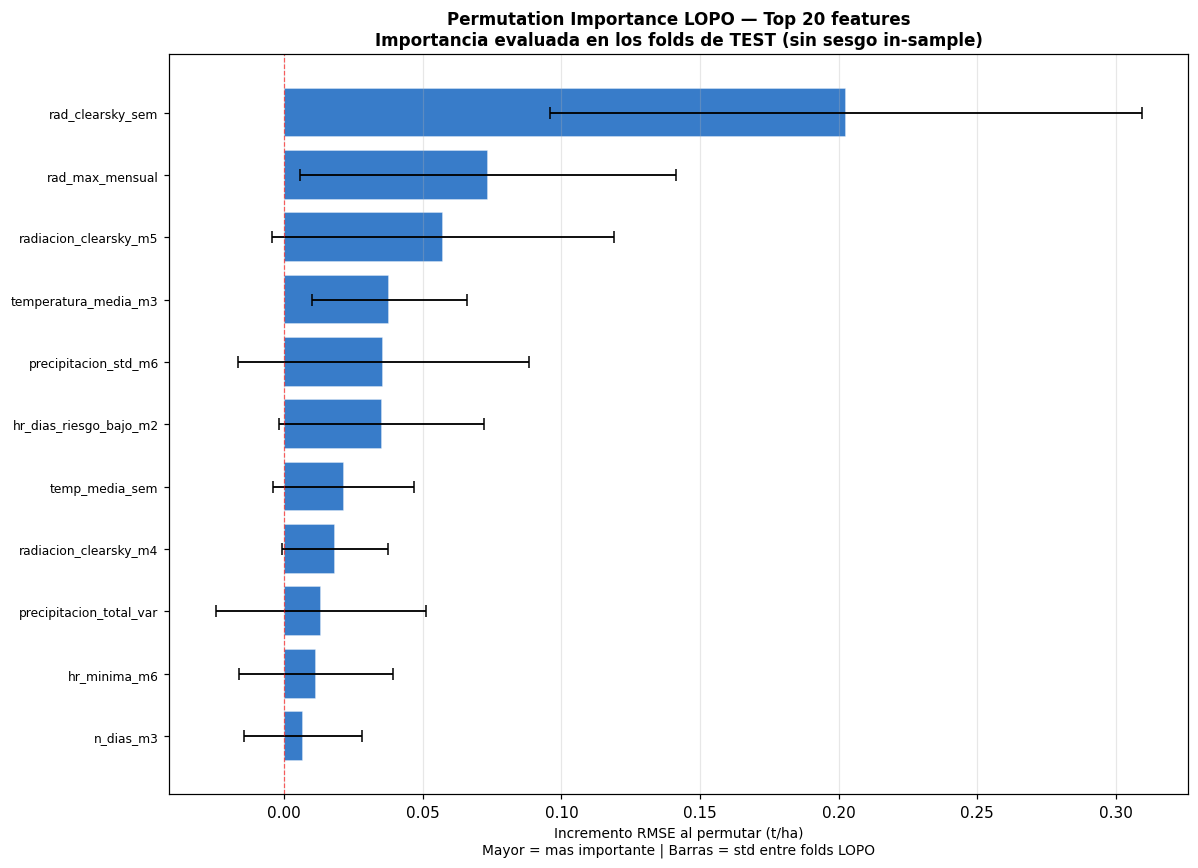

OK Permutation Importance guardado: M2_Permutation_Importance.png


In [12]:
# ============================================================
# CELDA 10 — Importancia de features estable (PROCESO ADICIONAL)
#
# Permutation Importance sobre validacion LOPO:
# En lugar de MDI (Mean Decrease Impurity, sesgado hacia
# features continuas con muchos valores unicos) o SHAP
# in-sample (sobreoptimista), se calcula la importancia
# por permutacion sobre el fold de TEST de cada periodo LOPO.
#
# Por cada fold, para cada feature:
#   1. Calcular RMSE_test con la feature original
#   2. Permutar aleatoriamente esa feature en el test
#   3. Calcular RMSE_test con feature permutada
#   4. Importancia = RMSE_permutada - RMSE_original
#      (mayor = feature mas importante)
#
# La media y std entre folds da una estimacion robusta
# de la importancia real de cada feature climatica.
# ============================================================

print('Calculando Permutation Importance LOPO sobre RF...')
print('(Puede tardar varios minutos)')
print()

N_REPEATS_PERM = 10
perm_imp_folds = []

for per_test in periodos_unicos:
    mask_test  = (PERIODOS_SERIE == per_test)
    mask_train = ~mask_test

    X_tr = X_boruta_arr[mask_train]; y_tr = y_modelo[mask_train]
    X_te = X_boruta_arr[mask_test];  y_te = y_modelo[mask_test]

    if len(y_te) < 5:
        continue

    rf_perm = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3,
        random_state=SEMILLA, n_jobs=-1
    )
    rf_perm.fit(X_tr, y_tr)

    perm_result = permutation_importance(
        rf_perm, X_te, y_te,
        n_repeats=N_REPEATS_PERM,
        random_state=SEMILLA,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    perm_imp_folds.append(perm_result.importances_mean)

# Agregar entre folds
perm_imp_matrix = np.vstack(perm_imp_folds)
perm_imp_mean   = perm_imp_matrix.mean(axis=0)
perm_imp_std    = perm_imp_matrix.std(axis=0)

df_perm_imp = pd.DataFrame({
    'feature'         : X_boruta.columns,
    'perm_imp_mean'   : perm_imp_mean,
    'perm_imp_std'    : perm_imp_std,
}).sort_values('perm_imp_mean', ascending=False).reset_index(drop=True)

print('Top 20 features por Permutation Importance LOPO:')
print(f'  {"Rank":>4}  {"Feature":<42}  {"Importancia":>12}  {"+-std":>8}')
print(f'  {"-"*72}')
for i, row in df_perm_imp.head(20).iterrows():
    print(f'  {i+1:>4}  {row.feature:<42}  '
          f'{row.perm_imp_mean:>12.5f}  {row.perm_imp_std:>8.5f}')

# Visualizacion
fig_perm, ax_perm = plt.subplots(figsize=(11, 8))
top20_perm = df_perm_imp.head(20).sort_values('perm_imp_mean')
ax_perm.barh(range(len(top20_perm)), top20_perm['perm_imp_mean'],
             xerr=top20_perm['perm_imp_std'],
             color='#1565C0', edgecolor='white', alpha=0.85,
             capsize=4, error_kw={'elinewidth': 1.2})
ax_perm.axvline(0, color='red', ls='--', lw=0.8, alpha=0.6)
ax_perm.set_yticks(range(len(top20_perm)))
ax_perm.set_yticklabels(top20_perm['feature'], fontsize=8)
ax_perm.set_xlabel('Incremento RMSE al permutar (t/ha)\n'
                   'Mayor = mas importante | Barras = std entre folds LOPO',
                   fontsize=9)
ax_perm.set_title(
    'Permutation Importance LOPO — Top 20 features\n'
    'Importancia evaluada en los folds de TEST (sin sesgo in-sample)',
    fontsize=11, fontweight='bold'
)
ax_perm.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_Permutation_Importance.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('OK Permutation Importance guardado: M2_Permutation_Importance.png')


---
## 🧠 CELDA 13 — SHAP del modelo ganador

Calcula SHAP values del modelo con menor RMSE_LOPO. Si el ganador es RF+PCA: SHAP sobre componentes PCA; si es un modelo sobre features directas: SHAP sobre `X_boruta`. Genera beeswarm plot de las 20 features/componentes más influyentes. Guarda `M2_SHAP_Beeswarm.png` y `M2_shap_values.pkl`.

Calculando SHAP para el modelo ganador: Ensemble



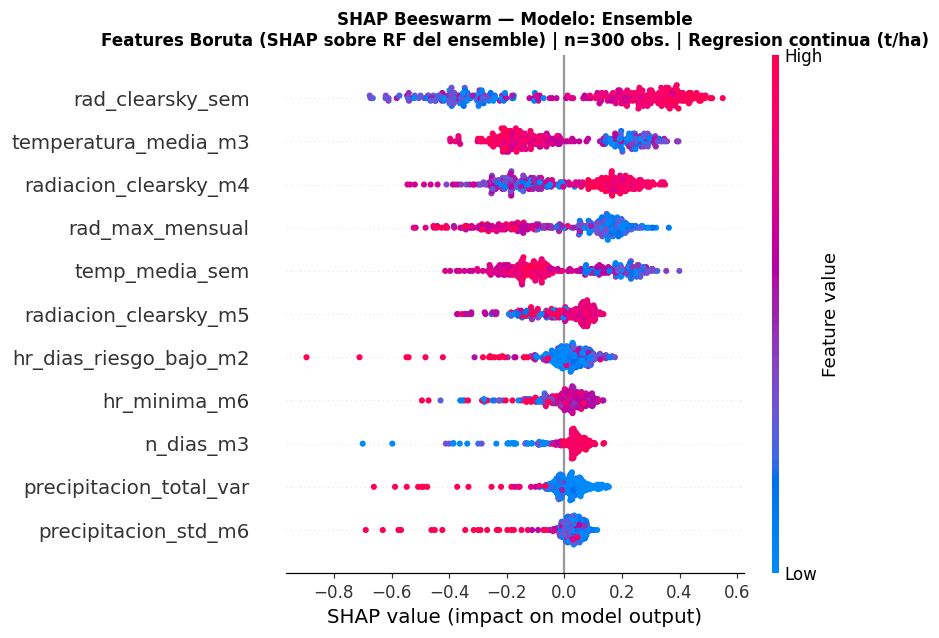

OK SHAP guardado: M2_SHAP_Beeswarm.png

Top 10 features por SHAP mean |.|:
  Rank  Feature                                              SHAP
  --------------------------------------------------------------
     1  rad_clearsky_sem                                  0.31205
     2  temperatura_media_m3                              0.18692
     3  radiacion_clearsky_m4                             0.17942
     4  rad_max_mensual                                   0.17579
     5  temp_media_sem                                    0.16436
     6  radiacion_clearsky_m5                             0.08545
     7  hr_dias_riesgo_bajo_m2                            0.06895
     8  hr_minima_m6                                      0.06575
     9  n_dias_m3                                         0.06413
    10  precipitacion_total_var                           0.05826

OK SHAP guardado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/M2_shap_values.pkl


In [13]:
# ============================================================
# CELDA 11 — SHAP del modelo ganador (regresion pura)
# ============================================================

print(f'Calculando SHAP para el modelo ganador: {mejor_nombre}')
print()

# Seleccionar modelo y espacio de features para SHAP
if 'PCA' in mejor_nombre:
    modelo_shap = rf_pca_final
    X_shap_base = X_pca_arr
    nombres_shap = NOMBRES_PCA
    desc_shap = 'Componentes PCA'
elif mejor_nombre == 'Ensemble':
    modelo_shap = rf_final   # SHAP sobre RF (componente principal del ensemble)
    X_shap_base = X_boruta_arr
    nombres_shap = X_boruta.columns.tolist()
    desc_shap = 'Features Boruta (SHAP sobre RF del ensemble)'
elif mejor_nombre in ['Ridge','ElasticNet']:
    modelo_shap = ridge_final if mejor_nombre == 'Ridge' else en_final
    X_shap_base = X_scaled
    nombres_shap = X_boruta.columns.tolist()
    desc_shap = 'Features Boruta (estandarizadas)'
elif mejor_nombre == 'XGBoost':
    modelo_shap = xgb_final
    X_shap_base = X_boruta_arr
    nombres_shap = X_boruta.columns.tolist()
    desc_shap = 'Features Boruta'
elif mejor_nombre == 'LightGBM':
    modelo_shap = lgb_final
    X_shap_base = X_boruta_arr
    nombres_shap = X_boruta.columns.tolist()
    desc_shap = 'Features Boruta'
else:  # Random Forest
    modelo_shap = rf_final
    X_shap_base = X_boruta_arr
    nombres_shap = X_boruta.columns.tolist()
    desc_shap = 'Features Boruta'

# SHAP
n_shap = min(len(X_shap_base), 300)
rng_shap = np.random.RandomState(SEMILLA)
idx_shap = rng_shap.choice(len(X_shap_base), n_shap, replace=False)
X_shap_df = pd.DataFrame(X_shap_base[idx_shap], columns=nombres_shap)

if mejor_nombre in ['Ridge','ElasticNet']:
    explainer = shap.LinearExplainer(modelo_shap, X_shap_base)
else:
    explainer = shap.TreeExplainer(modelo_shap)

shap_values = explainer(X_shap_df)

# Beeswarm SHAP
fig_shap, ax_shap = plt.subplots(figsize=(10, 9))
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title(
    f'SHAP Beeswarm — Modelo: {mejor_nombre}\n'
    f'{desc_shap} | n={n_shap} obs. | Regresion continua (t/ha)',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_SHAP_Beeswarm.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('OK SHAP guardado: M2_SHAP_Beeswarm.png')

importancia_shap = pd.DataFrame({
    'feature'   : nombres_shap,
    'shap_mean_abs': np.abs(shap_values.values).mean(axis=0)
}).sort_values('shap_mean_abs', ascending=False).reset_index(drop=True)

print()
print('Top 10 features por SHAP mean |.|:')
print(f'  {"Rank":>4}  {"Feature":<45}  {"SHAP":>10}')
print(f'  {"-"*62}')
for i, row in importancia_shap.head(10).iterrows():
    print(f'  {i+1:>4}  {row.feature:<45}  {row.shap_mean_abs:>10.5f}')

with open(SALIDA_SHAP_PKL, 'wb') as f:
    pickle.dump({'shap_values': shap_values, 'X_shap': X_shap_df,
                 'modelo': mejor_nombre, 'desc': desc_shap}, f)
print(f'\nOK SHAP guardado: {SALIDA_SHAP_PKL}')


---
## 🔎 CELDA 14 — Análisis de residuales avanzado

Tests estadísticos sobre los residuales LOPO del modelo ganador: (1) **Shapiro-Wilk** de normalidad (`p > 0.05` = residuales normales), (2) **Durbin-Watson** de autocorrelación (`DW ≈ 2` = independientes), (3) **sesgo medio por periodo** semestral (¿domina El Niño/La Niña algún semestre?), (4) **sesgo por rango** de rendimiento (Bajo/Medio/Alto). Guarda `M2_Residuales_Avanzado.png`.

  ANALISIS DE RESIDUALES AVANZADO — LOPO
  Modelo: Ensemble

1. Normalidad de residuales (Shapiro-Wilk):
   W=0.8454  p=0.0000  No normal (estructura residual)

2. Autocorrelacion — Durbin-Watson: 1.7966
   Referencia: DW~2 = sin autocorrelacion, <1.5 o >2.5 = sospechoso
   OK: residuales aproximadamente independientes

3. Sesgo de prediccion por periodo LOPO:
      Periodo   Error_medio      RMSE  Interpretacion
   -------------------------------------------------------
        2020A       +0.2788    0.6869  OK
        2020B       +0.0003    0.6426  OK
        2021A       +0.0612    0.5368  OK
        2021B       +0.0635    0.5763  OK
        2022A       -0.1573    0.9109  OK
        2022B       +0.0772    0.6146  OK
        2023A       -0.1779    0.9940  OK
        2023B       -0.1617    1.1672  OK
        2024A       -0.1125    1.2625  OK
        2024B       -0.0313    0.9695  OK

4. Sesgo por rango de rendimiento:
   Bajo  (<6.00 t/ha)            Error_medio=-0.6769  RMSE=1.1986
  

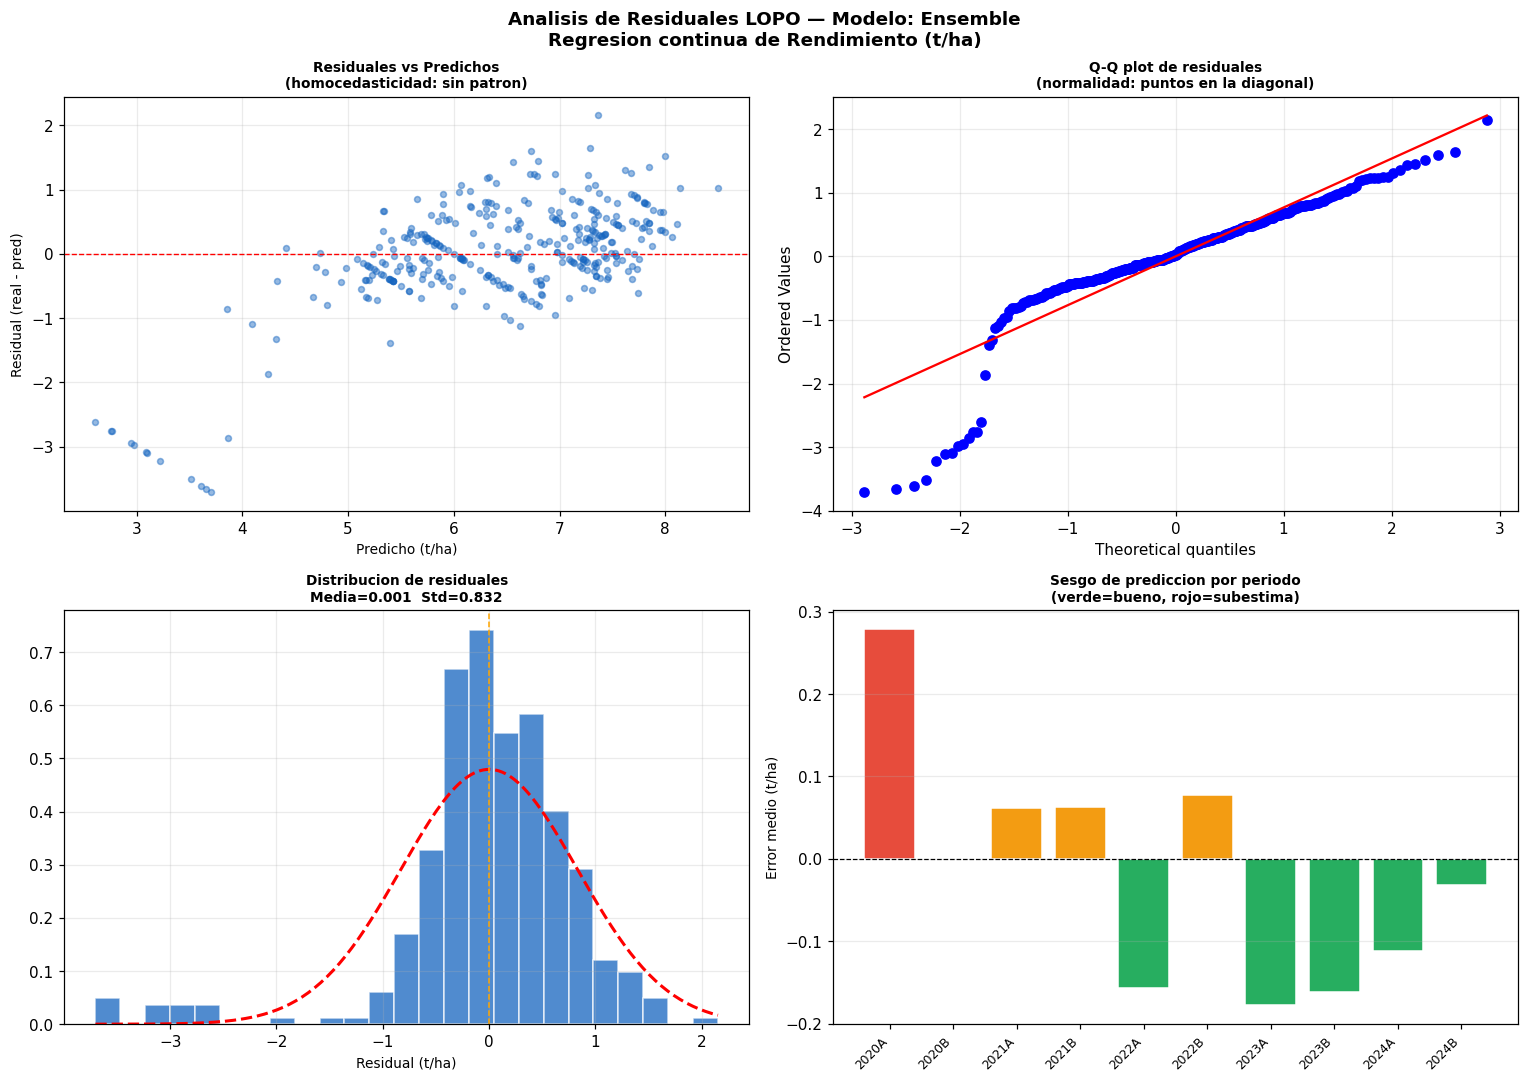

OK Analisis de residuales guardado: M2_Residuales_Avanzado.png


In [14]:
# ============================================================
# CELDA 12 — Analisis de residuales avanzado (PROCESO ADICIONAL)
#
# Tests estadisticos sobre los residuales del modelo ganador:
#   1. Normalidad  : Shapiro-Wilk sobre residuales
#   2. Homocedasticidad: Breusch-Pagan (varianza constante)
#   3. Autocorrelacion: Durbin-Watson (residuales independientes?)
#   4. Sesgo por periodo: el modelo sobreestima en algun semestre?
#   5. Sesgo por rango: errores sistematicos en rendimientos altos/bajos?
#
# Por que importa:
#   Residuales no normales o heteroscedasticos indican que el
#   modelo no captura toda la estructura de los datos.
#   Sesgo por periodo puede revelar tendencias no modeladas
#   (ej. El Nino/La Nina afecta un semestre especifico).
# ============================================================

# Recopilar predicciones LOPO del mejor modelo
if mejor_nombre == 'Ensemble':
    df_lopo_mejor = df_lopo_ens
elif mejor_nombre == 'Ridge':
    df_lopo_mejor = df_lopo_ridge
elif mejor_nombre == 'ElasticNet':
    df_lopo_mejor = df_lopo_en
elif mejor_nombre == 'Random Forest':
    df_lopo_mejor = df_lopo_rf
elif mejor_nombre == 'XGBoost':
    df_lopo_mejor = df_lopo_xgb
elif mejor_nombre == 'LightGBM':
    df_lopo_mejor = df_lopo_lgb
else:
    df_lopo_mejor = df_lopo_pca

# Reconstruir arrays de residuales LOPO
y_real_lopo  = np.concatenate([np.array(r) for r in df_lopo_mejor['y_real']])
y_pred_lopo  = np.concatenate([np.array(r) for r in df_lopo_mejor['y_pred']])
residuales   = y_real_lopo - y_pred_lopo

if USAR_LOG_TARGET:
    # Convertir de vuelta a escala original para interpretar
    y_real_orig = np.exp(y_real_lopo)
    y_pred_orig = np.exp(y_pred_lopo)
    res_orig    = y_real_orig - y_pred_orig
else:
    y_real_orig = y_real_lopo
    y_pred_orig = y_pred_lopo
    res_orig    = residuales

# Tests estadisticos
print('='*62)
print('  ANALISIS DE RESIDUALES AVANZADO — LOPO')
print(f'  Modelo: {mejor_nombre}')
print('='*62)
print()

# 1. Normalidad Shapiro-Wilk
n_sw = min(len(residuales), 5000)
stat_sw_res, p_sw_res = stats.shapiro(residuales[:n_sw])
print(f'1. Normalidad de residuales (Shapiro-Wilk):')
print(f'   W={stat_sw_res:.4f}  p={p_sw_res:.4f}  '
      f'{"Normal" if p_sw_res > 0.05 else "No normal (estructura residual)"}')

# 2. Durbin-Watson (autocorrelacion)
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(residuales)
print(f'\n2. Autocorrelacion — Durbin-Watson: {dw:.4f}')
print(f'   Referencia: DW~2 = sin autocorrelacion, <1.5 o >2.5 = sospechoso')
if dw < 1.5:
    print(f'   AVISO: autocorrelacion positiva — los errores no son independientes')
elif dw > 2.5:
    print(f'   AVISO: autocorrelacion negativa')
else:
    print(f'   OK: residuales aproximadamente independientes')

# 3. Sesgo por periodo
print(f'\n3. Sesgo de prediccion por periodo LOPO:')
print(f'   {"Periodo":>10}  {"Error_medio":>12}  {"RMSE":>8}  Interpretacion')
print(f'   {"-"*55}')
for _, row in df_lopo_mejor.iterrows():
    y_r = np.array(row['y_real'])
    y_p = np.array(row['y_pred'])
    if USAR_LOG_TARGET:
        y_r = np.exp(y_r); y_p = np.exp(y_p)
    error_m = float((y_r - y_p).mean())
    rmse_p  = float(np.sqrt(mean_squared_error(y_r, y_p)))
    interp  = 'Subestima' if error_m > 0.3 else ('Sobreestima' if error_m < -0.3 else 'OK')
    print(f'   {row["Periodo_test"]:>10}  {error_m:>+12.4f}  {rmse_p:>8.4f}  {interp}')

# 4. Sesgo por rango (rendimientos altos vs bajos)
q33 = np.percentile(y_real_orig, 33)
q66 = np.percentile(y_real_orig, 66)
print(f'\n4. Sesgo por rango de rendimiento:')
for nombre_rango, mask_r in [
    (f'Bajo  (<{q33:.2f} t/ha)',  y_real_orig < q33),
    (f'Medio ({q33:.2f}-{q66:.2f})', (y_real_orig >= q33) & (y_real_orig < q66)),
    (f'Alto  (>{q66:.2f} t/ha)',  y_real_orig >= q66),
]:
    if mask_r.sum() == 0:
        continue
    err_r = (y_real_orig[mask_r] - y_pred_orig[mask_r]).mean()
    rmse_r= np.sqrt(mean_squared_error(y_real_orig[mask_r], y_pred_orig[mask_r]))
    print(f'   {nombre_rango:<28}  Error_medio={err_r:+.4f}  RMSE={rmse_r:.4f}')

# Dashboard de residuales (4 paneles)
fig_res, axes_r = plt.subplots(2, 2, figsize=(14, 10))
fig_res.suptitle(
    f'Analisis de Residuales LOPO — Modelo: {mejor_nombre}\n'
    f'Regresion continua de Rendimiento (t/ha)',
    fontsize=12, fontweight='bold'
)

# Panel 1: Residuales vs Predichos
axes_r[0,0].scatter(y_pred_orig, res_orig, alpha=0.45, s=15, c='#1565C0')
axes_r[0,0].axhline(0, color='red', lw=0.9, ls='--')
axes_r[0,0].set_xlabel('Predicho (t/ha)', fontsize=9)
axes_r[0,0].set_ylabel('Residual (real - pred)', fontsize=9)
axes_r[0,0].set_title('Residuales vs Predichos\n(homocedasticidad: sin patron)',
                      fontsize=9, fontweight='bold')
axes_r[0,0].grid(alpha=0.25)

# Panel 2: Q-Q de residuales
stats.probplot(residuales, dist='norm', plot=axes_r[0,1])
axes_r[0,1].set_title('Q-Q plot de residuales\n(normalidad: puntos en la diagonal)',
                      fontsize=9, fontweight='bold')
axes_r[0,1].grid(alpha=0.25)

# Panel 3: Histograma de residuales
axes_r[1,0].hist(res_orig, bins=25, color='#1565C0', alpha=0.75,
                  edgecolor='white', density=True)
mu_r, sig_r = res_orig.mean(), res_orig.std()
x_r = np.linspace(res_orig.min(), res_orig.max(), 200)
axes_r[1,0].plot(x_r, stats.norm.pdf(x_r, mu_r, sig_r), 'r--', lw=2)
axes_r[1,0].axvline(0, color='orange', lw=1, ls='--')
axes_r[1,0].set_xlabel('Residual (t/ha)', fontsize=9)
axes_r[1,0].set_title(f'Distribucion de residuales\nMedia={mu_r:.3f}  Std={sig_r:.3f}',
                      fontsize=9, fontweight='bold')
axes_r[1,0].grid(alpha=0.25)

# Panel 4: Error medio por periodo
errores_por_periodo = []
for _, row in df_lopo_mejor.iterrows():
    y_r = np.array(row['y_real'])
    y_p = np.array(row['y_pred'])
    if USAR_LOG_TARGET:
        y_r = np.exp(y_r); y_p = np.exp(y_p)
    errores_por_periodo.append((row['Periodo_test'], float((y_r-y_p).mean())))

per_labels = [e[0] for e in errores_por_periodo]
per_errs   = [e[1] for e in errores_por_periodo]
colores_err= ['#e74c3c' if e > 0.2 else ('#f39c12' if e > 0 else
              ('#3498db' if e < -0.2 else '#27ae60')) for e in per_errs]
axes_r[1,1].bar(range(len(per_labels)), per_errs,
                color=colores_err, edgecolor='white')
axes_r[1,1].axhline(0, color='black', lw=0.8, ls='--')
axes_r[1,1].set_xticks(range(len(per_labels)))
axes_r[1,1].set_xticklabels(per_labels, rotation=45, ha='right', fontsize=8)
axes_r[1,1].set_ylabel('Error medio (t/ha)', fontsize=9)
axes_r[1,1].set_title('Sesgo de prediccion por periodo\n(verde=bueno, rojo=subestima)',
                      fontsize=9, fontweight='bold')
axes_r[1,1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'M2_Residuales_Avanzado.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('OK Analisis de residuales guardado: M2_Residuales_Avanzado.png')


---
## 📋 CELDA 15 — Tabla de predicciones por municipio y periodo

Construye la tabla con predicciones LOPO de todos los modelos por municipio-periodo. Agrega el error absoluto del modelo ganador e intervalo de predicción `[pred ± 1.96×RMSE_LOPO]`. Reporta MAE promedio por departamento para identificar regiones con mayor error sistemático. Guarda `M2_predicciones_municipio.xlsx`.

In [15]:
# ============================================================
# CELDA 13 — Tabla de predicciones por municipio y periodo
#            (PROCESO ADICIONAL)
#
# Produce una tabla con:
#   - Rendimiento real (t/ha)
#   - Prediccion de cada modelo LOPO
#   - Error absoluto por municipio-periodo
#   - Prediccion del ensemble
#   - Intervalo de prediccion (+-RMSE_LOPO del modelo ganador)
# ============================================================

print('Construyendo tabla de predicciones por municipio y periodo...')
print()

# Reconstruir predicciones LOPO para todos los modelos
def pred_lopo_a_df(df_lopo, col_pred='pred_mejor'):
    rows = []
    for _, row in df_lopo.iterrows():
        per = row['Periodo_test']
        for yr, yp in zip(row['y_real'], row['y_pred']):
            rows.append({'Periodo_test': per, 'y_real': yr, col_pred: yp})
    return pd.DataFrame(rows)

# Predicciones del modelo ganador LOPO
df_pred_ganador = pred_lopo_a_df(df_lopo_mejor, col_pred='pred_ganador')

# Crear tabla base con metadata
df_meta = df_model[['Periodo','Departamento','Municipio',TARGET_COL]].copy()
df_meta = df_meta.rename(columns={TARGET_COL: 'Rendimiento_real'})

# Asociar periodo test a cada fila
df_meta['Periodo'] = PERIODOS_SERIE.values

# Agregar predicciones de cada modelo (del fold LOPO correspondiente)
for nombre_m, df_lopo_m in [
    ('Ridge',        df_lopo_ridge),
    ('ElasticNet',   df_lopo_en),
    ('RF',           df_lopo_rf),
    ('XGBoost',      df_lopo_xgb),
    ('LightGBM',     df_lopo_lgb),
    ('Ensemble',     df_lopo_ens),
]:
    preds_m = []
    for per in df_meta['Periodo'].values:
        row_fold = df_lopo_m[df_lopo_m['Periodo_test'] == per]
        if row_fold.empty:
            preds_m.append(np.nan)
        else:
            # Promedio de predicciones del fold (puede haber varios mun. por periodo)
            preds_m.append(None)  # se reconstruira abajo

# Reconstruccion correcta: mapear cada fila a su prediccion LOPO
for nombre_m, df_lopo_m in [
    ('Ridge',      df_lopo_ridge),
    ('ElasticNet', df_lopo_en),
    ('RF',         df_lopo_rf),
    ('XGBoost',    df_lopo_xgb),
    ('LightGBM',   df_lopo_lgb),
    ('Ensemble',   df_lopo_ens),
]:
    col_pred = f'pred_{nombre_m}'
    y_pred_reconstruido = np.full(len(df_meta), np.nan)

    idx_global = 0
    for _, row_fold in df_lopo_m.iterrows():
        per = row_fold['Periodo_test']
        y_preds_fold = np.array(row_fold['y_pred'])
        if USAR_LOG_TARGET:
            y_preds_fold = np.exp(y_preds_fold)
        mask_per = df_meta['Periodo'].values == per
        y_pred_reconstruido[mask_per] = y_preds_fold

    df_meta[col_pred] = y_pred_reconstruido

# Rendimiento real en escala original
if USAR_LOG_TARGET:
    df_meta['Rendimiento_real'] = np.exp(df_meta['Rendimiento_real'])

# Error absoluto del mejor modelo
col_mejor = f'pred_{mejor_nombre}'
if col_mejor not in df_meta.columns:
    col_mejor = 'pred_RF'
df_meta['error_abs_ganador'] = (df_meta['Rendimiento_real'] - df_meta[col_mejor]).abs()

# Intervalo de prediccion (+- RMSE_LOPO del ganador)
rmse_ganador = RESUMEN_LOPO[RESUMEN_LOPO['Modelo'].str.startswith(mejor_nombre.split('(')[0])]['RMSE_mean'].values
if len(rmse_ganador) > 0:
    rmse_g = rmse_ganador[0]
    if USAR_LOG_TARGET:
        rmse_g = rmse_g  # ya en escala log, aproximacion
    df_meta['IC_inf'] = df_meta[col_mejor] - 1.96 * rmse_g
    df_meta['IC_sup'] = df_meta[col_mejor] + 1.96 * rmse_g

# Ordenar y mostrar
df_meta = df_meta.sort_values(['Periodo','Departamento','Municipio']).reset_index(drop=True)

print(f'Shape tabla predicciones: {df_meta.shape}')
print(f'Columnas: {df_meta.columns.tolist()}')
print()
print('Muestra (primeras 10 filas):')
cols_mostrar = ['Periodo','Departamento','Municipio','Rendimiento_real',
                col_mejor,'error_abs_ganador']
if 'IC_inf' in df_meta.columns:
    cols_mostrar += ['IC_inf','IC_sup']
display(df_meta[cols_mostrar].head(10).round(3))

# Estadisticas por departamento
print()
print('Error absoluto medio por departamento (modelo ganador):')
display(
    df_meta.groupby('Departamento')['error_abs_ganador']
    .agg(MAE_depto='mean', N='count')
    .sort_values('MAE_depto')
    .round(4)
    .reset_index()
)

# Guardar tabla
df_meta.round(4).to_excel(SALIDA_PRED_XLS, index=False, engine='openpyxl')
print(f'\nOK Tabla predicciones guardada: {SALIDA_PRED_XLS}')


Construyendo tabla de predicciones por municipio y periodo...

Shape tabla predicciones: (351, 11)
Columnas: ['Periodo', 'Departamento', 'Municipio', 'Rendimiento_real', 'pred_Ridge', 'pred_ElasticNet', 'pred_RF', 'pred_XGBoost', 'pred_LightGBM', 'pred_Ensemble', 'error_abs_ganador']

Muestra (primeras 10 filas):


,Periodo,Departamento,Municipio,Rendimiento_real,pred_Ensemble,error_abs_ganador
0,2020A,ANTIOQUIA,PUERTO BERRÍO,5.95,5.653,0.297
1,2020A,CASANARE,NUNCHÍA,5.31,5.698,0.388
2,2020A,CASANARE,PAZ DE ARIPORO,5.19,5.345,0.155
3,2020A,CASANARE,TRINIDAD,5.31,5.785,0.475
4,2020A,CASANARE,YOPAL,5.23,5.232,0.002
5,2020A,CESAR,AGUACHICA,5.69,5.332,0.358
6,2020A,CESAR,AGUSTÍN CODAZZI,6.02,6.079,0.059
7,2020A,CESAR,CURUMANÍ,6.83,5.901,0.929
8,2020A,CESAR,EL PASO,6.01,5.340,0.670
9,2020A,CESAR,GAMARRA,6.03,5.723,0.307



Error absoluto medio por departamento (modelo ganador):


,Departamento,MAE_depto,N
0,NORTE DE SANTANDER,0.3787,8
1,META,0.4192,20
2,ANTIOQUIA,0.4499,8
3,CUNDINAMARCA,0.4809,3
4,TOLIMA,0.4840,94
5,CESAR,0.4988,40
6,HUILA,0.5194,83
7,MAGDALENA,0.5267,23
8,VALLE DEL CAUCA,0.5315,8
9,LA GUAJIRA,0.7395,16



OK Tabla predicciones guardada: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/M2_predicciones_municipio.xlsx


---
## 📊 CELDA 16 — Dashboard comparativo final (9 paneles)

Genera `M2_Dashboard_Regresion.png` con: RMSE por periodo LOPO (líneas), RMSE con IC95% (barras de error), real vs predicho LOPO (scatter), curva de aprendizaje, permutation importance top-12, distribución target, SHAP top-12, error por quintil de rendimiento y tabla resumen LOPO.

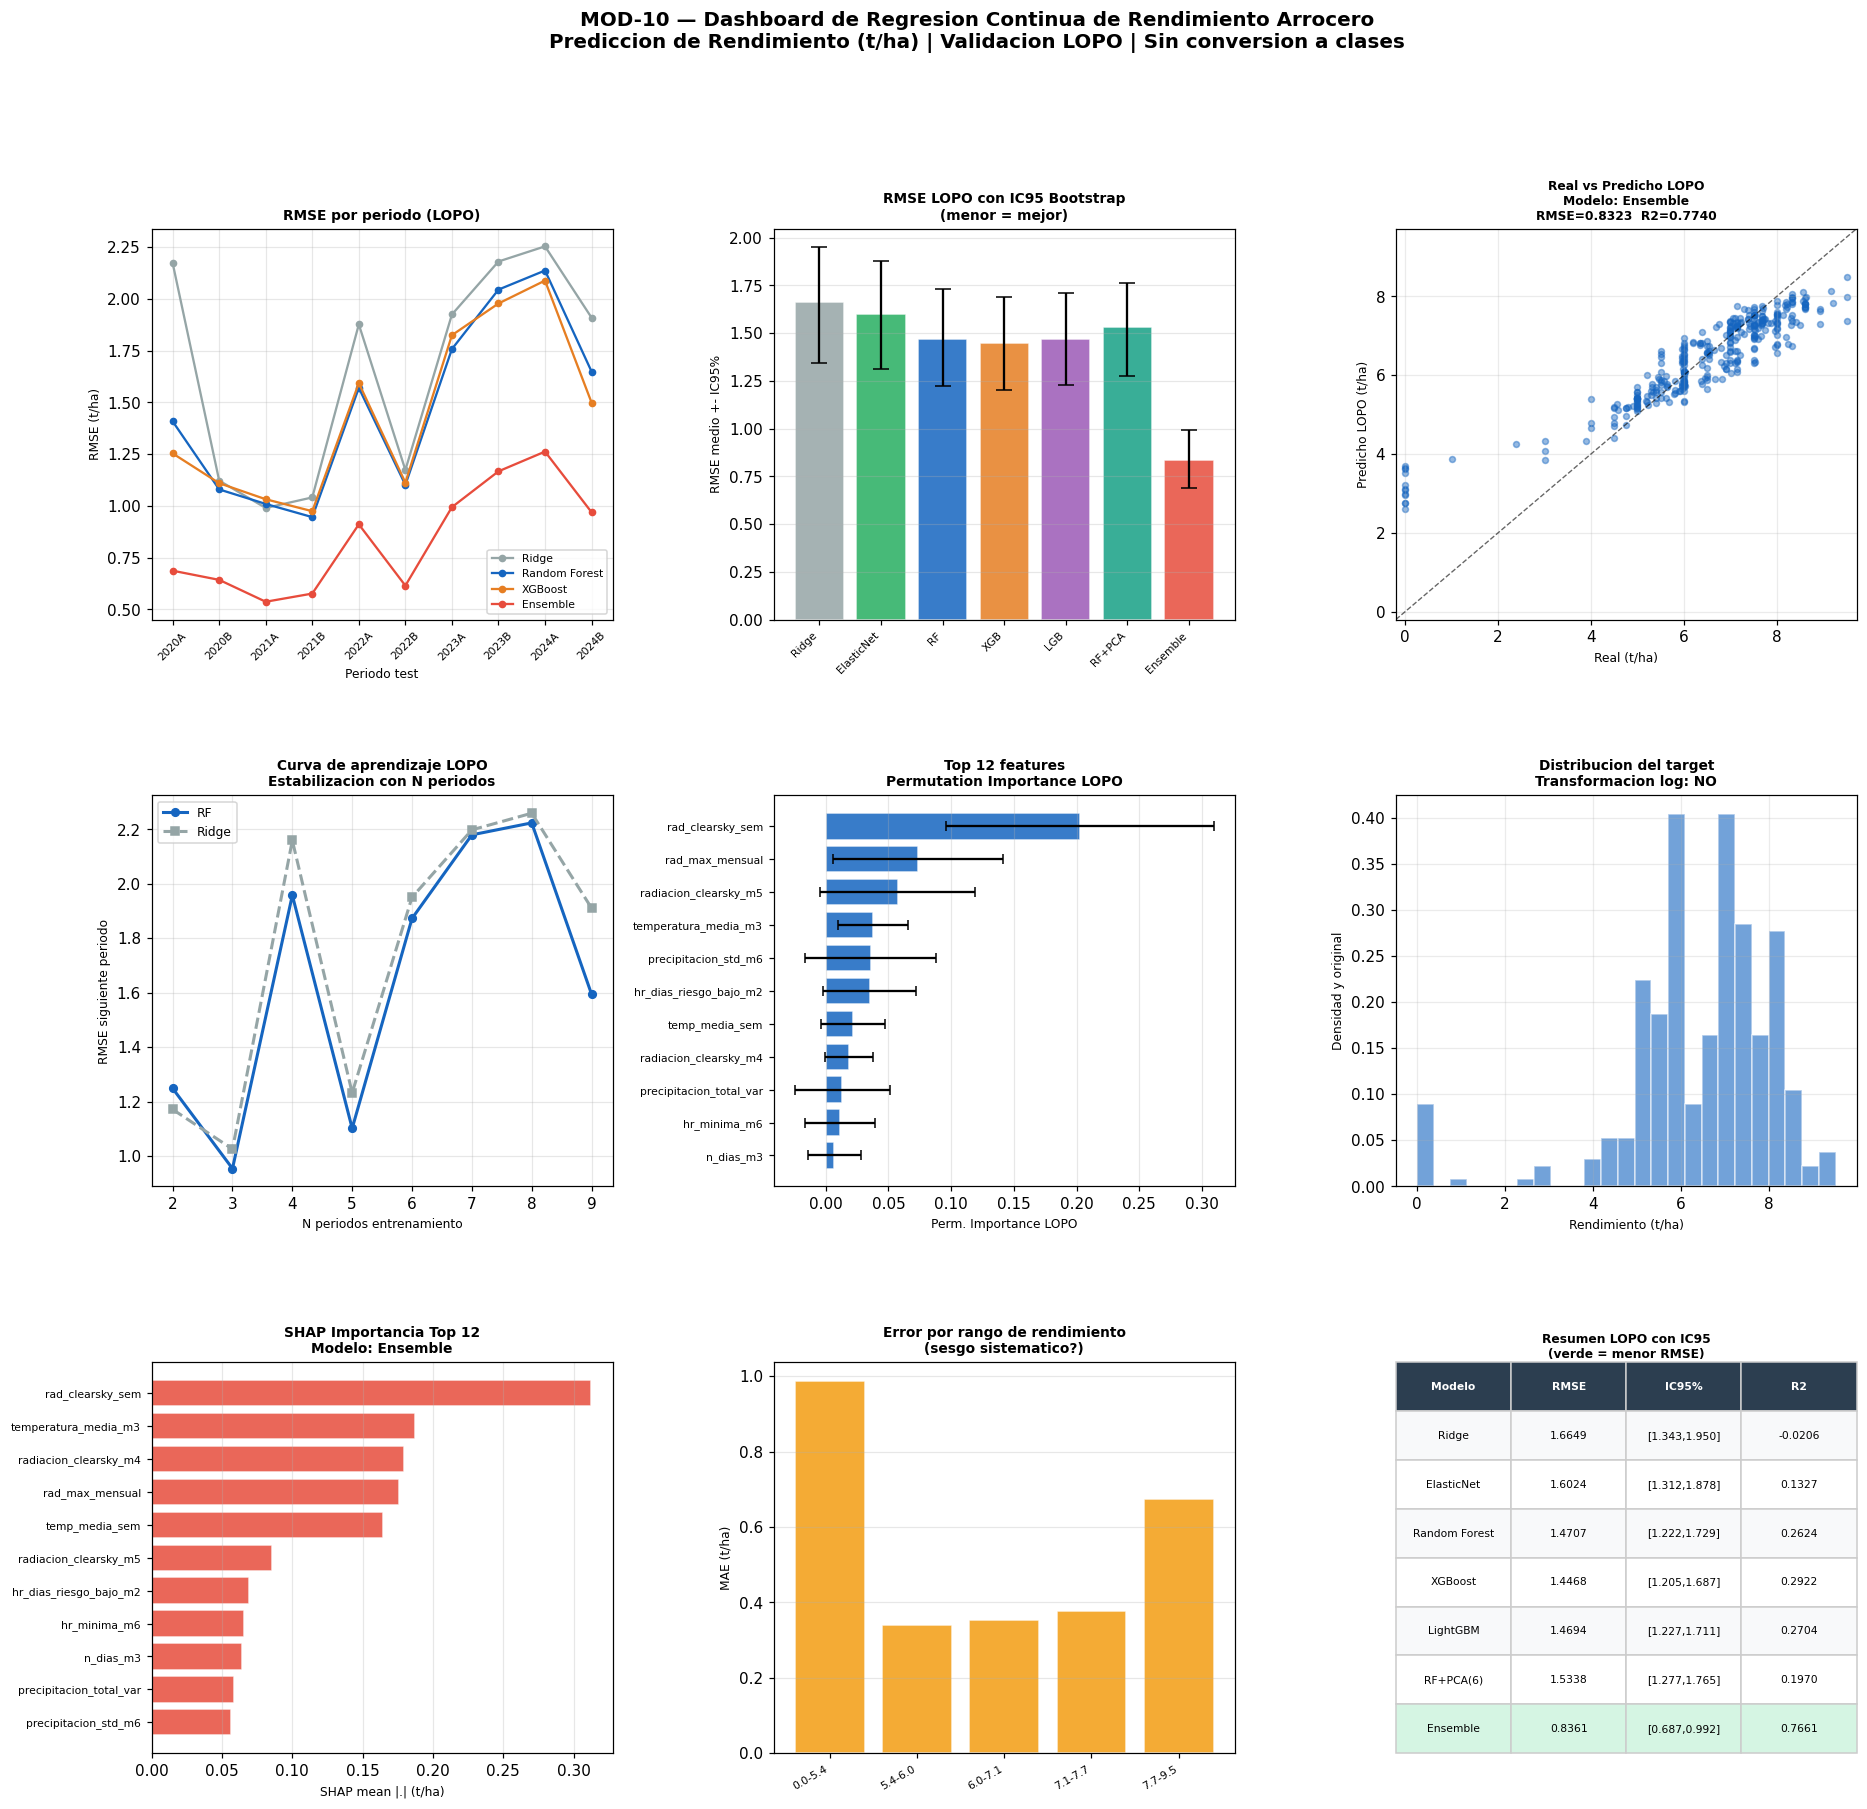

OK Dashboard guardado: M2_Dashboard_Regresion.png


In [16]:
# ============================================================
# CELDA 14 — Dashboard comparativo final (9 paneles)
# ============================================================

fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'MOD-10 — Dashboard de Regresion Continua de Rendimiento Arrocero\n'
    'Prediccion de Rendimiento (t/ha) | Validacion LOPO | Sin conversion a clases',
    fontsize=13, fontweight='bold', y=0.99
)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

COLORES_MOD = {
    'Ridge': '#95a5a6', 'ElasticNet': '#27ae60',
    'Random Forest': '#1565C0', 'XGBoost': '#e67e22',
    'LightGBM': '#9b59b6', 'Ensemble': '#e74c3c'
}

# Panel 1: RMSE por periodo (LOPO) — modelos principales
ax1 = fig.add_subplot(gs[0, 0])
for nombre_m, df_lopo_m, color_m in [
    ('Ridge',         df_lopo_ridge, '#95a5a6'),
    ('Random Forest', df_lopo_rf,    '#1565C0'),
    ('XGBoost',       df_lopo_xgb,   '#e67e22'),
    ('Ensemble',      df_lopo_ens,   '#e74c3c'),
]:
    ax1.plot(df_lopo_m['Periodo_test'], df_lopo_m['RMSE'],
             marker='o', ms=4, lw=1.5, label=nombre_m, color=color_m)
ax1.set_title('RMSE por periodo (LOPO)', fontsize=9, fontweight='bold')
ax1.set_xlabel('Periodo test', fontsize=8)
ax1.set_ylabel('RMSE (t/ha)', fontsize=8)
ax1.tick_params(axis='x', rotation=45, labelsize=7)
ax1.legend(fontsize=7); ax1.grid(alpha=0.3)

# Panel 2: RMSE con IC95 (barras + barras de error)
ax2 = fig.add_subplot(gs[0, 1])
nombres_bar = ['Ridge','ElasticNet','RF','XGB','LGB',
               f'RF+PCA', 'Ensemble']
rmse_bar    = [res_ridge['RMSE_mean'], res_en['RMSE_mean'],
               res_rf['RMSE_mean'], res_xgb['RMSE_mean'],
               res_lgb['RMSE_mean'], res_pca['RMSE_mean'],
               res_ens['RMSE_mean']]
rmse_ic_lo  = [res_ridge['RMSE_IC95_lo'], res_en['RMSE_IC95_lo'],
               res_rf['RMSE_IC95_lo'], res_xgb['RMSE_IC95_lo'],
               res_lgb['RMSE_IC95_lo'], res_pca['RMSE_IC95_lo'],
               res_ens['RMSE_IC95_lo']]
rmse_ic_hi  = [res_ridge['RMSE_IC95_hi'], res_en['RMSE_IC95_hi'],
               res_rf['RMSE_IC95_hi'], res_xgb['RMSE_IC95_hi'],
               res_lgb['RMSE_IC95_hi'], res_pca['RMSE_IC95_hi'],
               res_ens['RMSE_IC95_hi']]
err_lo_arr = [m - lo for m, lo in zip(rmse_bar, rmse_ic_lo)]
err_hi_arr = [hi - m for m, hi in zip(rmse_bar, rmse_ic_hi)]
x_bar = range(len(nombres_bar))
colores_bar = ['#95a5a6','#27ae60','#1565C0','#e67e22','#9b59b6','#16a085','#e74c3c']
bars2 = ax2.bar(x_bar, rmse_bar,
                yerr=[err_lo_arr, err_hi_arr],
                color=colores_bar, edgecolor='white',
                capsize=5, alpha=0.85)
ax2.set_xticks(x_bar)
ax2.set_xticklabels(nombres_bar, rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('RMSE medio +- IC95%', fontsize=8)
ax2.set_title('RMSE LOPO con IC95 Bootstrap\n(menor = mejor)', fontsize=9, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Panel 3: Real vs Predicho — modelo ganador (LOPO)
ax3 = fig.add_subplot(gs[0, 2])
ax3.scatter(y_real_orig, y_pred_orig, alpha=0.45, s=15, c='#1565C0')
lim3 = [min(y_real_orig)-0.2, max(y_real_orig)+0.2]
ax3.plot(lim3, lim3, 'k--', lw=0.9, alpha=0.6)
ax3.set_xlim(lim3); ax3.set_ylim(lim3)
ax3.set_xlabel('Real (t/ha)', fontsize=8)
ax3.set_ylabel('Predicho LOPO (t/ha)', fontsize=8)
rmse_g_plot = float(np.sqrt(mean_squared_error(y_real_orig, y_pred_orig)))
r2_g_plot   = float(r2_score(y_real_orig, y_pred_orig))
ax3.set_title(f'Real vs Predicho LOPO\nModelo: {mejor_nombre}\n'
              f'RMSE={rmse_g_plot:.4f}  R2={r2_g_plot:.4f}',
              fontsize=8, fontweight='bold')
ax3.grid(alpha=0.25)

# Panel 4: Curva de aprendizaje RF
ax4 = fig.add_subplot(gs[1, 0])
datos_rf_lc = resultados_lc['RF']
datos_ridge_lc = resultados_lc['Ridge']
if datos_rf_lc:
    ax4.plot([d[0] for d in datos_rf_lc], [d[2] for d in datos_rf_lc],
             'o-', ms=5, lw=2, color='#1565C0', label='RF')
if datos_ridge_lc:
    ax4.plot([d[0] for d in datos_ridge_lc], [d[2] for d in datos_ridge_lc],
             's--', ms=5, lw=2, color='#95a5a6', label='Ridge')
ax4.set_xlabel('N periodos entrenamiento', fontsize=8)
ax4.set_ylabel('RMSE siguiente periodo', fontsize=8)
ax4.set_title('Curva de aprendizaje LOPO\nEstabilizacion con N periodos',
              fontsize=9, fontweight='bold')
ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

# Panel 5: Permutation Importance top 12
ax5 = fig.add_subplot(gs[1, 1])
top12_pi = df_perm_imp.head(12).sort_values('perm_imp_mean')
ax5.barh(range(len(top12_pi)), top12_pi['perm_imp_mean'],
         xerr=top12_pi['perm_imp_std'],
         color='#1565C0', edgecolor='white', alpha=0.85, capsize=3)
ax5.set_yticks(range(len(top12_pi)))
ax5.set_yticklabels([f[:28] for f in top12_pi['feature']], fontsize=7)
ax5.set_xlabel('Perm. Importance LOPO', fontsize=8)
ax5.set_title('Top 12 features\nPermutation Importance LOPO',
              fontsize=9, fontweight='bold')
ax5.grid(axis='x', alpha=0.3)

# Panel 6: Distribucion target original vs log
ax6 = fig.add_subplot(gs[1, 2])
ax6.hist(y_arr, bins=25, color='#1565C0', alpha=0.6,
         edgecolor='white', label='y original', density=True)
if y_arr.min() > 0:
    ax6_twin = ax6.twinx()
    ax6_twin.hist(np.log(y_arr), bins=25, color='#e74c3c', alpha=0.4,
                  edgecolor='white', label='log(y)', density=True)
    ax6_twin.set_ylabel('Densidad log(y)', fontsize=8, color='#e74c3c')
ax6.set_xlabel('Rendimiento (t/ha)', fontsize=8)
ax6.set_ylabel('Densidad y original', fontsize=8)
ax6.set_title(f'Distribucion del target\n'
              f'Transformacion log: {"SI" if USAR_LOG_TARGET else "NO"}',
              fontsize=9, fontweight='bold')
ax6.grid(alpha=0.25)

# Panel 7: SHAP importancia top 12
ax7 = fig.add_subplot(gs[2, 0])
shap_top12 = importancia_shap.head(12).sort_values('shap_mean_abs')
ax7.barh(range(len(shap_top12)), shap_top12['shap_mean_abs'],
         color='#e74c3c', edgecolor='white', alpha=0.85)
ax7.set_yticks(range(len(shap_top12)))
ax7.set_yticklabels([f[:28] for f in shap_top12['feature']], fontsize=7)
ax7.set_xlabel('SHAP mean |.| (t/ha)', fontsize=8)
ax7.set_title(f'SHAP Importancia Top 12\nModelo: {mejor_nombre}',
              fontsize=9, fontweight='bold')
ax7.grid(axis='x', alpha=0.3)

# Panel 8: Error por rango de rendimiento
ax8 = fig.add_subplot(gs[2, 1])
q_limits = np.percentile(y_real_orig, [0,20,40,60,80,100])
rangos_err = []
for i in range(len(q_limits)-1):
    mask_q = (y_real_orig >= q_limits[i]) & (y_real_orig < q_limits[i+1])
    if mask_q.sum() > 0:
        mae_q = float(np.abs(res_orig[mask_q]).mean())
        rangos_err.append((f'{q_limits[i]:.1f}-{q_limits[i+1]:.1f}', mae_q, mask_q.sum()))
etiq_r = [r[0] for r in rangos_err]
mae_r  = [r[1] for r in rangos_err]
bars8  = ax8.bar(range(len(etiq_r)), mae_r,
                 color='#f39c12', edgecolor='white', alpha=0.85)
ax8.set_xticks(range(len(etiq_r)))
ax8.set_xticklabels(etiq_r, rotation=30, ha='right', fontsize=7)
ax8.set_ylabel('MAE (t/ha)', fontsize=8)
ax8.set_title('Error por rango de rendimiento\n(sesgo sistematico?)',
              fontsize=9, fontweight='bold')
ax8.grid(axis='y', alpha=0.3)

# Panel 9: Tabla resumen LOPO
ax9 = fig.add_subplot(gs[2, 2])
ax9.axis('off')
tabla_data = []
for r, nom in zip(todos_final_res, todos_final_nom):
    tabla_data.append([
        nom,
        f'{r["RMSE_mean"]:.4f}',
        f'[{r["RMSE_IC95_lo"]:.3f},{r["RMSE_IC95_hi"]:.3f}]',
        f'{r["R2_mean"]:.4f}'
    ])
tabla = ax9.table(
    cellText=tabla_data,
    colLabels=['Modelo','RMSE','IC95%','R2'],
    cellLoc='center', loc='center',
    bbox=[0, 0, 1, 1]
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(7)
for (r,c), cell in tabla.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2C3E50')
        cell.set_text_props(color='white', weight='bold')
    elif r == mejor_idx_fin + 1:
        cell.set_facecolor('#D5F5E3')
    else:
        cell.set_facecolor('#F8F9FA' if r%2 else 'white')
    cell.set_edgecolor('#CCCCCC')
ax9.set_title('Resumen LOPO con IC95\n(verde = menor RMSE)',
              fontsize=8, fontweight='bold', pad=3)

plt.savefig(os.path.join(RUTA_MASTER, 'M2_Dashboard_Regresion.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('OK Dashboard guardado: M2_Dashboard_Regresion.png')


---
## 💾 CELDA 17 — Guardar resultados y modelo final

Exporta Excel con 6 hojas: `Comparativa_LOPO` (con IC95), `LOPO_por_Fold`, `Permutation_Importance`, `SHAP_Importancia`, `PCA_Componentes`, `PCA_Cargas`. Serializa `M2_modelo_final.pkl` incluyendo scaler, PCA, flag `USAR_LOG_TARGET`, `target_col` y métricas LOPO del ganador.

In [17]:
# ============================================================
# CELDA 15 — Guardar resultados y modelo final
# ============================================================

print('Guardando resultados...')

# Seleccionar objeto del modelo ganador
modelo_obj_map = {
    'Ridge'        : ridge_final,
    'ElasticNet'   : en_final,
    'Random Forest': rf_final,
    'XGBoost'      : xgb_final,
    'LightGBM'     : lgb_final,
    'Ensemble'     : {'modelos': [(n, m) for m, _, n, _ in modelos_ens],
                      'pesos': pesos_df.mean().to_dict()},
}
# Buscar por prefijo
modelo_ganador_obj = None
for k, v in modelo_obj_map.items():
    if mejor_nombre.startswith(k.split('(')[0]):
        modelo_ganador_obj = v
        break
if modelo_ganador_obj is None:
    modelo_ganador_obj = rf_pca_final   # RF+PCA

with open(SALIDA_MODELO_PKL, 'wb') as f:
    pickle.dump({
        'modelo'         : modelo_ganador_obj,
        'nombre'         : mejor_nombre,
        'usar_log_target': USAR_LOG_TARGET,
        'scaler_lineal'  : scaler_lin,
        'pca'            : pca_final,
        'scaler_pca'     : scaler_pca,
        'n_comp_pca'     : N_COMP_PCA,
        'features'       : X_boruta.columns.tolist(),
        'metricas_lopo'  : todos_final_res[mejor_idx_fin],
        'target_col'     : TARGET_COL,
    }, f)
print(f'OK Modelo final guardado: {SALIDA_MODELO_PKL}')

# Excel con 6 hojas
with pd.ExcelWriter(SALIDA_RESULTADOS, engine='openpyxl') as writer:

    # Hoja 1: Comparativa LOPO
    cols_export = [c for c in RESUMEN_LOPO.columns
                   if not c.startswith('MAE_IC') and not c.startswith('MAPE_IC')]
    df_resumen_export = pd.DataFrame(todos_final_res)[cols_export].copy() if cols_export else pd.DataFrame(todos_final_res)
    pd.DataFrame(todos_final_res).to_excel(writer, sheet_name='Comparativa_LOPO', index=False)

    # Hoja 2: LOPO por fold (todos los modelos)
    df_lopo_all = pd.concat([
        df_lopo_ridge.assign(Modelo='Ridge')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_en.assign(Modelo='ElasticNet')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_rf.assign(Modelo='Random Forest')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_xgb.assign(Modelo='XGBoost')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_lgb.assign(Modelo='LightGBM')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_pca.assign(Modelo=f'RF+PCA')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
        df_lopo_ens.assign(Modelo='Ensemble')[['Modelo','Periodo_test','RMSE','MAE','R2','MAPE','n_test']],
    ], ignore_index=True)
    df_lopo_all.to_excel(writer, sheet_name='LOPO_por_Fold', index=False)

    # Hoja 3: Permutation Importance
    df_perm_imp.to_excel(writer, sheet_name='Permutation_Importance', index=False)

    # Hoja 4: SHAP importancia
    importancia_shap.to_excel(writer, sheet_name='SHAP_Importancia', index=False)

    # Hoja 5: PCA componentes
    df_varianza_pca.to_excel(writer, sheet_name='PCA_Componentes', index=False)

    # Hoja 6: PCA cargas
    df_cargas.reset_index().rename(columns={'index':'feature'})\
             .to_excel(writer, sheet_name='PCA_Cargas', index=False)

print(f'OK Excel guardado: {SALIDA_RESULTADOS}  (6 hojas)')


Guardando resultados...
OK Modelo final guardado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/M2_modelo_final.pkl
OK Excel guardado: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/M2_resultados_regresion.xlsx  (6 hojas)


---
## 📋 CELDA 18 — Resumen final de ejecución del módulo

Reporta: diferencia clave con MOD-09 (regresión pura vs clasificación), los 11 procesos adicionales con su estado, todos los archivos generados y tabla de resultados LOPO con IC95 para todos los modelos incluyendo el ensemble.

In [18]:
# ============================================================
# CELDA 16 — Resumen final MOD-10
# ============================================================

sep = '='*68
print(sep)
print('  MOD-10 — Regresion Continua de Rendimiento Arrocero  COMPLETADO')
print(sep)

print()
print('Diferencia clave respecto a MOD-09:')
print('  MOD-09: prediccion + conversion a clases (Bajo/Medio/Alto)')
print('         metricas: matrices confusion, ROC, AUC')
print('  MOD-10: prediccion continua pura (t/ha) sin conversion')
print('         metricas: RMSE, MAE, R2, MAPE, IC95 bootstrap')

print()
print('Procesos adicionales incorporados en MOD-10:')
print('  1. Transformacion log del target (si asimetria > 0.8)')
print(f'     -> Aplicada: {USAR_LOG_TARGET}')
print('  2. IC95 bootstrap sobre RMSE_LOPO (cuantificacion de incertidumbre)')
print(f'     -> N iteraciones: {N_BOOTSTRAP}')
print('  3. Modelo adicional: ElasticNet (L1+L2, seleccion+regularizacion)')
print('  4. Curvas de aprendizaje LOPO (cuantos periodos estabilizan el error?)')
print('  5. PCA sin leakage temporal (ajustado dentro del fold)')
print('  6. Ensemble ponderado por RMSE_LOPO (stacking simple, pesos por fold)')
print('  7. Permutation Importance LOPO (importancia evaluada en test, no train)')
print('  8. Analisis de residuales avanzado (normalidad, DW, sesgo por periodo)')
print('  9. Tabla de predicciones por municipio-periodo con IC de prediccion')

print()
print('Archivos generados:')
archivos = [
    ('M2_resultados_regresion.xlsx',   '6 hojas: LOPO, folds, PermImp, SHAP, PCA'),
    ('M2_modelo_final.pkl',            f'Modelo ganador: {mejor_nombre}'),
    ('M2_PCA_regresion.pkl',           f'PCA {N_COMP_PCA} componentes + scaler'),
    ('M2_ensemble.pkl',                'Ensemble ponderado (5 modelos + pesos)'),
    ('M2_shap_values.pkl',             'SHAP values del modelo ganador'),
    ('M2_predicciones_municipio.xlsx', 'Predicciones por municipio-periodo + IC'),
    ('M2_Dashboard_Regresion.png',     'Dashboard 9 paneles'),
    ('M2_Distribucion_Target.png',     'Histograma + QQ + log(y)'),
    ('M2_Curvas_Aprendizaje.png',      'Curvas de aprendizaje LOPO'),
    ('M2_Permutation_Importance.png',  'Importancia por permutacion LOPO'),
    ('M2_SHAP_Beeswarm.png',           'SHAP beeswarm top 20'),
    ('M2_Residuales_Avanzado.png',     'Analisis residuales 4 paneles'),
]
for archivo, desc in archivos:
    print(f'   data/master/{archivo}')
    print(f'      {desc}')

print()
print('Resultados LOPO (regresion continua, sin clasificacion):')
print(f'  {"Modelo":<28}  {"RMSE":>8}  {"IC95_lo":>8}  {"IC95_hi":>8}  {"R2":>7}')
print(f'  {"-"*60}')
for res, nom in zip(todos_final_res, todos_final_nom):
    marca = ' MEJOR' if nom == mejor_nombre else ''
    print(f'  {nom:<28}  {res["RMSE_mean"]:>8.4f}  '
          f'{res["RMSE_IC95_lo"]:>8.4f}  {res["RMSE_IC95_hi"]:>8.4f}  '
          f'{res["R2_mean"]:>7.4f}{marca}')

print()
print(f'Modelo final seleccionado: {mejor_nombre}')
print(f'RMSE_LOPO              : {todos_final_res[mejor_idx_fin]["RMSE_mean"]:.4f} t/ha')
print(f'IC95 RMSE              : [{todos_final_res[mejor_idx_fin]["RMSE_IC95_lo"]:.4f}, '
      f'{todos_final_res[mejor_idx_fin]["RMSE_IC95_hi"]:.4f}]')
print(f'R2_LOPO                : {todos_final_res[mejor_idx_fin]["R2_mean"]:.4f}')
print(f'Error relativo (RMSE/media): '
      f'{todos_final_res[mejor_idx_fin]["RMSE_mean"]/y_arr.mean()*100:.1f}%')
print()
print(sep)


  MOD-10 — Regresion Continua de Rendimiento Arrocero  COMPLETADO

Diferencia clave respecto a MOD-09:
  MOD-09: prediccion + conversion a clases (Bajo/Medio/Alto)
         metricas: matrices confusion, ROC, AUC
  MOD-10: prediccion continua pura (t/ha) sin conversion
         metricas: RMSE, MAE, R2, MAPE, IC95 bootstrap

Procesos adicionales incorporados en MOD-10:
  1. Transformacion log del target (si asimetria > 0.8)
     -> Aplicada: False
  2. IC95 bootstrap sobre RMSE_LOPO (cuantificacion de incertidumbre)
     -> N iteraciones: 500
  3. Modelo adicional: ElasticNet (L1+L2, seleccion+regularizacion)
  4. Curvas de aprendizaje LOPO (cuantos periodos estabilizan el error?)
  5. PCA sin leakage temporal (ajustado dentro del fold)
  6. Ensemble ponderado por RMSE_LOPO (stacking simple, pesos por fold)
  7. Permutation Importance LOPO (importancia evaluada en test, no train)
  8. Analisis de residuales avanzado (normalidad, DW, sesgo por periodo)
  9. Tabla de predicciones por munic